# SentinelX AI — Baseline RUL sur NASA C-MAPSS FD001

**Étape S3 · Modèles de référence pour la prédiction du Remaining Useful Life (RUL)**

| Élément | Valeur |
|---|---|
| Projet | SentinelX AI — plateforme de maintenance prédictive & Maintenance Copilot RAG |
| Notebook | `02_baseline_fd001.ipynb` (version 2) |
| Étape précédente | `01_eda_fd001_final_fusion.ipynb` (EDA terminée et validée) |
| Code réutilisable | `ml/src/` : `data.py`, `features.py`, `evaluation.py`, `models.py` (testés par `pytest`) |
| Exigences couvertes | F-03 (feature pipeline), F-04 (baseline reproductible), F-06 (comparaison train / validation / test) · backlog B05, B06 |
| Definition of Done (README §10) | Baseline RUL entraîné, `baseline_metrics.json` et graphiques, **sans fuite d'information** |
| Étape suivante | S4 — modèle séquentiel LSTM / GRU, comparé à ce baseline sur le même protocole |
| Durée d'exécution | ≈ 20 minutes sur un PC à 2 cœurs (la Random Forest représente l'essentiel du calcul) ; plus rapide avec plus de cœurs |

### Objectif de S3

Construire des **modèles de référence** (*baselines*) qui prédisent le RUL d'un moteur à partir de ses mesures. Un baseline sert d'**étalon** : le LSTM / GRU de S4 n'aura d'intérêt que s'il fait **mesurablement mieux**, sur le même protocole.

### Nouveautés de la version 2

| Version 1 | Version 2 |
|---|---|
| Linear Regression et Ridge | + **Random Forest Regressor** (modèle non linéaire) |
| 17 mesures au cycle courant | + **features temporelles causales** : moyenne et pente sur 30 cycles, écart au début de vie |
| Fonctions définies dans le notebook | Fonctions déplacées dans `ml/src/` et **testées** (README §10.2, étape 1) |
| Règle « gain > 1 écart-type » | Règle **appariée** : une option doit gagner sur **chacun** des 5 folds |
| Choix du modèle implicite | **Sélection explicite** sur la validation, enregistrée dans `model_selection.json` **avant** la lecture du test |
| `RUL_FD001.txt` protégé par convention | Protégé par code : `GroundTruthGuard` refuse toute lecture avant le gel du pipeline, et toute seconde lecture |

### Questions auxquelles ce notebook répond

| # | Question | Sections |
|---|---|---|
| Q1 | Que valent les trois modèles sur les seules mesures instantanées ? | 7 |
| Q2 | Les features temporelles apportent-elles un gain réel, et pour quel modèle ? | 8 |
| Q3 | Quel plafond de RUL et quels hyperparamètres pour chaque modèle ? | 9, 10 |
| Q4 | Quel modèle retenir, sur un critère objectif et sans regarder le test ? | 11 |
| Q5 | Les décisions « à valider » de l'EDA changent-elles le résultat ? | 12 |
| Q6 | Où le modèle se trompe-t-il, et sur quoi s'appuie-t-il ? | 14, 15 |
| Q7 | Quelle performance réelle sur le jeu de test officiel NASA ? | 17 |

### Règles anti-fuite appliquées (README §9)

1. **Split par moteur** : le split figé de l'EDA est réutilisé tel quel.
2. **Toute la sélection** (features, plafond, hyperparamètres, modèle) se fait en **validation croisée GroupKFold** sur les 80 moteurs d'analyse, puis est **vérifiée** sur les 20 moteurs de validation figés.
3. **`RUL_FD001.txt` est lu une seule fois**, en section 17, après le gel du pipeline. Le code l'impose.
4. **Aucune variable future** : `unit_id`, `RUL`, `max_cycle`, `life_pct`… sont refusés par `check_features`.
5. **Features temporelles causales** : elles n'utilisent que le passé du moteur, sans traverser deux trajectoires (testé par `pytest`).
6. **Preprocessing ajusté sur le train uniquement** : le `StandardScaler` est dans un `Pipeline`, réajusté à chaque fold.
7. **Aucune métrique inventée** : chaque chiffre de la conclusion est revérifié par la section 20.

### Sommaire

0. Introduction · 1. Configuration · 2. Données et décisions de l'EDA · 3. Cible RUL · 4. Features de base · 5. Features temporelles causales · 6. Outils de modélisation et d'évaluation · 7. Premier comparatif des trois modèles · 8. Choix des features temporelles · 9. Choix du plafond de RUL · 10. Hyperparamètres · 11. Sélection du modèle · 12. Ablations de l'EDA · 13. Prédictions négatives · 14. Vérification sur les 20 moteurs de validation · 15. Graphiques d'analyse · 16. Entraînement final, sauvegarde et gel · 17. Test NASA FD001 · 18. Sauvegarde des artefacts · 19. Conclusion · 20. Vérification automatique des chiffres

## 1. Configuration et reproductibilité

**Objectif.** Déclarer en un seul endroit les bibliothèques, la graine et **tous les paramètres d'expérience**. Les valeurs testées sont des choix déclarés à l'avance ; c'est la validation croisée qui décide.

Le notebook importe le code réutilisable depuis `ml/src/`. Il trouve automatiquement la racine du dépôt, qu'il soit lancé depuis la racine ou depuis `notebooks/` (VS Code, Jupyter local).

In [1]:
from pathlib import Path
import json
import platform
import sys
import time

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.inspection import permutation_importance

# --- Rendre le paquet `ml` importable : on remonte jusqu'à la racine du dépôt -----------
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "ml" / "src").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ml.src.data import (GroundTruthGuard, add_rul, check_raw_files, check_rul, file_sha256, find_project_root,
                         last_observed_cycles, load_cmapss, load_eda_decisions, split_by_engine)
from ml.src.evaluation import (cap_target, clip_negative, cross_validate, evaluate_predictions, group_folds,
                               paired_gain, regression_metrics, rul_band_table)
from ml.src.features import build_feature_set, candidate_features, check_features
from ml.src.models import MODEL_NAMES, make_model

assert find_project_root(PROJECT_ROOT) == PROJECT_ROOT

# --- Paramètres de l'expérience ------------------------------------------------------
RANDOM_STATE = 42                      # même graine que l'EDA
N_SPLITS = 5                           # GroupKFold : 80 moteurs -> 16 moteurs évalués par fold
REFERENCE_CAP = 110                    # plafond retenu en v1, point de départ de l'étape 8
RUL_CAPS = (90, 100, 110, 120, 125, 130, 140)          # plafonds testés à l'étape 9
RIDGE_ALPHAS = tuple(np.logspace(-3, 4, 15).round(6))   # grille d'alpha de 0,001 à 10 000
ALPHA_TOLERANCE = 0.01                 # cycles : écart de RMSE jugé négligeable entre deux alpha
RF_BASE_PARAMS = {"n_estimators": 100, "min_samples_leaf": 10, "max_features": 0.33}
RF_GRID = {"min_samples_leaf": (5, 10, 20), "max_features": (0.33, 0.5)}
REQUIRED_FOLDS_IMPROVED = N_SPLITS     # une option n'est adoptée que si elle gagne sur CHAQUE fold

# Jeux de features testés : base = 17 mesures ; mean/slope = fenêtre W (W <= 30, README §8.3) ;
# dev = nombre de cycles de début de vie servant de référence (le test a au moins 31 cycles).
FEATURE_SPECS = {
    "instantané": {},
    "moyenne 30": {"mean": 30},
    "pente 30": {"slope": 30},
    "écart début de vie 20": {"dev": 20},
    "moyenne 30 + pente 30": {"mean": 30, "slope": 30},
    "moyenne 30 + pente 30 + écart 20": {"mean": 30, "slope": 30, "dev": 20},
}
RUL_BANDS = (0, 25, 75, 127, np.inf)   # proche panne / milieu / fin de zone utile / moteur sain
SAVE_OUTPUTS = True

# --- Style graphique : 3 premiers emplacements de la palette de référence (validés pour 3 séries)
MODEL_COLORS = {"LinearRegression": "#2a78d6", "Ridge": "#eb6834", "RandomForest": "#1baf7a"}
MODEL_LABELS = {"LinearRegression": "Linear Regression", "Ridge": "Ridge", "RandomForest": "Random Forest"}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": "#c9c8c3", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_2, "ytick.color": INK_2, "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 4)

VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
            "seaborn": sns.__version__, "joblib": joblib.__version__}
NOTEBOOK_START = time.time()
pd.Series(VERSIONS, name="version").to_frame().T

,python,numpy,pandas,scikit-learn,matplotlib,seaborn,joblib
version,3.13.16,2.5.3,3.0.6,1.9.1,3.11.2,0.13.2,1.6.0


In [2]:
RAW_DIR = PROJECT_ROOT / "data" / "raw"
check_raw_files(RAW_DIR)   # message explicite si les fichiers FD001 ne sont pas dans data/raw/
TRAIN_PATH, TEST_PATH, RUL_TEST_PATH = (RAW_DIR / n for n in ("train_FD001.txt", "test_FD001.txt", "RUL_FD001.txt"))

EDA_ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "eda_fd001"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "baseline_fd001"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "baseline_fd001"
for directory in (ARTIFACT_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)


def save_figure(fig, name):
    # Enregistre la figure dans reports/figures/baseline_fd001/.
    if SAVE_OUTPUTS:
        fig.savefig(FIGURE_DIR / f"{name}.png")


print("Racine du projet :", PROJECT_ROOT)

Racine du projet : /root/repro


## 2. Chargement des données et des décisions de l'EDA

**Objectif.** Charger le train FD001 et **relire** les décisions figées de l'EDA (split par moteur, groupes de variables) au lieu de les refaire.

> **Rappel — pourquoi un split par moteur ?** Les cycles successifs d'un même moteur se ressemblent énormément. Si des cycles du moteur 7 étaient à la fois en apprentissage et en évaluation, le modèle « reconnaîtrait » le moteur et le score serait faussement bon : c'est une **fuite d'information** (*data leakage*).

Les empreintes SHA-256 des fichiers sont comparées à celles de l'EDA : si un fichier avait changé, le notebook s'arrêterait ici.

In [3]:
eda_summary, engine_split, feature_groups = load_eda_decisions(EDA_ARTIFACT_DIR)

RAW_SHA256 = {p.name: file_sha256(p) for p in (TRAIN_PATH, TEST_PATH)}
for name, expected in eda_summary["raw_files_sha256"].items():
    assert RAW_SHA256[name] == expected, f"{name} : empreinte différente de l'EDA"

train_df = load_cmapss(TRAIN_PATH)
assert len(train_df) == eda_summary["train"]["n_rows"] and train_df["unit_id"].nunique() == 100

ANALYSIS_ENGINES = sorted(engine_split["analysis_engines"])
VALIDATION_ENGINES = sorted(engine_split["validation_engines"])
analysis_df, validation_df = split_by_engine(train_df, ANALYSIS_ENGINES, VALIDATION_ENGINES)
assert (len(analysis_df), len(validation_df)) == (16_561, 4_070)   # effectifs de l'EDA (README §8.2)

pd.DataFrame({"moteurs": [len(ANALYSIS_ENGINES), len(VALIDATION_ENGINES)],
              "lignes": [len(analysis_df), len(validation_df)],
              "rôle": ["apprentissage + validation croisée (sections 7 à 13)",
                       "vérification de la configuration choisie (section 14)"]},
             index=["analyse", "validation figée"])

,moteurs,lignes,rôle
analyse,80,16561,apprentissage + validation croisée (sections 7...
validation figée,20,4070,vérification de la configuration choisie (sect...


## 3. Construction de la cible RUL

> **Définition — RUL (Remaining Useful Life).** Nombre de cycles restant avant la défaillance. Si le moteur *i* tombe en panne au cycle $T_i$, alors au cycle $t$ : $\text{RUL}_i(t) = T_i - t$.

$T_i$ sert à **construire** la cible mais n'est jamais une feature (il révèle le futur) : `add_rul` le calcule sans l'ajouter au tableau.

**Horizon d'évaluation.** Les capteurs sont presque plats en début de vie (EDA §7) : prédire « 300 » plutôt que « 200 » pour un moteur sain ne dépend pas des mesures. Les modèles sont donc comparés sur la **zone utile** RUL réel ≤ `EVAL_HORIZON`, le plus grand RUL atteint par **tous** les moteurs d'analyse (127). Sous cet horizon, chaque moteur pèse autant dans la métrique.

In [4]:
analysis_df, validation_df, full_train_df = (add_rul(df) for df in (analysis_df, validation_df, train_df))
for frame in (analysis_df, validation_df, full_train_df):
    check_rul(frame)
assert round(analysis_df["RUL"].mean(), 4) == eda_summary["rul_analysis_train"]["mean"]

EVAL_HORIZON = int(analysis_df.groupby("unit_id")["cycle"].max().min() - 1)
assert EVAL_HORIZON == 127   # EDA : « tous les moteurs couvrent RUL 0 à 127 »
print(f"EVAL_HORIZON = {EVAL_HORIZON} cycles ; "
      f"{(analysis_df['RUL'] <= EVAL_HORIZON).mean():.1%} des lignes d'analyse sont dans la zone utile")

EVAL_HORIZON = 127 cycles ; 61.8% des lignes d'analyse sont dans la zone utile


## 4. Features de base (décisions de l'EDA)

> **Feature** : variable d'entrée du modèle. **Cible** (*target*) : ce qu'on veut prédire, le RUL.

| Décision EDA | Application |
|---|---|
| Retirer les **7 variables constantes** | `setting_3`, `sensor_1`, `5`, `10`, `16`, `18`, `19` exclues |
| Partir des **17 variables non constantes** | 16 dynamiques + `sensor_6` (quasi constante, testée en ablation) |
| Variables **interdites** | refusées automatiquement par `check_features` |
| `cycle`, `sensor_6`, `setting_1/2`, `sensor_9/14`, redondance | testés en ablation (section 12) |

In [5]:
CANDIDATE_FEATURES = candidate_features(feature_groups)
check_features(CANDIDATE_FEATURES, forbidden=feature_groups["forbidden_as_feature"])
assert len(CANDIDATE_FEATURES) == 17
assert set(CANDIDATE_FEATURES) == set(feature_groups["dynamic"]) | set(feature_groups["near_constant"])
CANDIDATE_SENSORS = [f for f in CANDIDATE_FEATURES if f.startswith("sensor_")]
print(f"{len(CANDIDATE_FEATURES)} features de base, dont {len(CANDIDATE_SENSORS)} capteurs :", CANDIDATE_FEATURES)

17 features de base, dont 15 capteurs : ['setting_1', 'setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 5. Features temporelles causales

**Objectif.** La v1 ne voyait qu'**un instant** : elle ne pouvait ni lisser le bruit de mesure, ni estimer la **vitesse** de dégradation, ni tenir compte de l'usure initiale propre à chaque moteur. On ajoute trois familles de features, calculées **moteur par moteur** :

| Famille | Définition au cycle *t* | Ce qu'elle apporte |
|---|---|---|
| **Moyenne glissante** `_mean30` | moyenne des 30 derniers cycles (cycles *t−29* à *t*) | lisse le bruit de mesure |
| **Pente glissante** `_slope30` | pente de la droite des moindres carrés sur les 30 derniers cycles (unités par cycle) | **vitesse** de dégradation : faible si le moteur est sain, forte près de la panne |
| **Écart au début de vie** `_dev20` | mesure courante − moyenne des 20 premiers cycles du moteur | retire le niveau de départ propre au moteur (usure initiale inconnue, EDA §2) |

> **Causalité.** Chaque feature au cycle *t* n'utilise que les cycles ≤ *t* du **même** moteur. En début de trajectoire, les calculs utilisent simplement les cycles déjà observés (`min_periods=1`). C'est indispensable : sur le test, on ne dispose que du passé. Ces propriétés sont vérifiées par les tests `ml/tests/test_features.py` et, ci-dessous, sur les vraies données.

Ces features n'ont **aucun paramètre appris** : on peut les calculer sur un jeu complet sans fuite, car elles ne mélangent ni les moteurs ni le futur.

In [6]:
FEATURE_CACHE = {}


def get_feature_set(df_name, spec_name, base=tuple(CANDIDATE_FEATURES)):
    # Construit (une seule fois) le jeu de features `spec_name` sur le DataFrame `df_name`.
    key = (df_name, spec_name, base)
    if key not in FEATURE_CACHE:
        source = {"analysis": analysis_df, "validation": validation_df, "full_train": full_train_df}[df_name]
        FEATURE_CACHE[key] = build_feature_set(source, list(base), FEATURE_SPECS[spec_name])
    return FEATURE_CACHE[key]


for spec_name in FEATURE_SPECS:
    df_feat, feats = get_feature_set("analysis", spec_name)
    check_features(feats, forbidden=feature_groups["forbidden_as_feature"])
    assert np.isfinite(df_feat[feats].to_numpy()).all(), f"{spec_name} : valeurs non finies"

# Contrôle de causalité sur un vrai moteur : on falsifie son futur, ses features passées ne bougent pas.
probe = analysis_df[analysis_df["unit_id"] == ANALYSIS_ENGINES[0]].copy()
spec = FEATURE_SPECS["moyenne 30 + pente 30 + écart 20"]
before, feats = build_feature_set(probe, CANDIDATE_FEATURES, spec)
probe.loc[probe["cycle"] > 60, CANDIDATE_SENSORS] += 1_000.0
after, _ = build_feature_set(probe, CANDIDATE_FEATURES, spec)
past = before["cycle"] <= 60
assert np.allclose(before.loc[past, feats], after.loc[past, feats])
print("Causalité vérifiée sur le moteur", ANALYSIS_ENGINES[0], ": le futur n'influence pas le passé.")

pd.DataFrame({"jeu de features": list(FEATURE_SPECS),
              "nombre de features": [len(get_feature_set("analysis", s)[1]) for s in FEATURE_SPECS]}).set_index("jeu de features").T

Causalité vérifiée sur le moteur 2 : le futur n'influence pas le passé.


jeu de features,instantané,moyenne 30,pente 30,écart début de vie 20,moyenne 30 + pente 30,moyenne 30 + pente 30 + écart 20
nombre de features,17,32,32,32,47,62


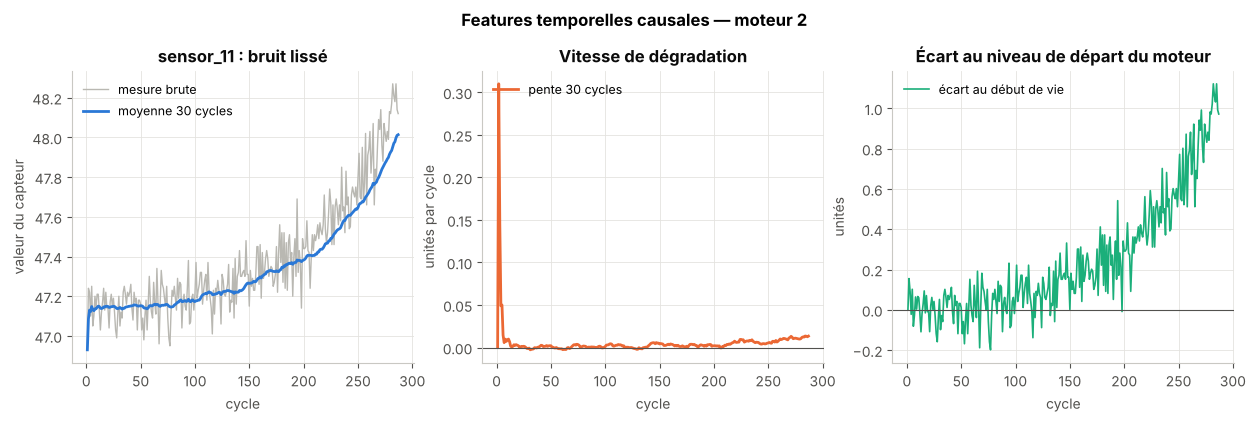

In [7]:
# Illustration : un capteur brut et ses trois features temporelles pour un moteur d'analyse.
unit = ANALYSIS_ENGINES[0]
df_feat, _ = get_feature_set("analysis", "moyenne 30 + pente 30 + écart 20")
eng = df_feat[df_feat["unit_id"] == unit]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True)
axes[0].plot(eng["cycle"], eng["sensor_11"], color="#b9b8b2", lw=1, label="mesure brute")
axes[0].plot(eng["cycle"], eng["sensor_11_mean30"], color=MODEL_COLORS["LinearRegression"], label="moyenne 30 cycles")
axes[0].set(title="sensor_11 : bruit lissé", ylabel="valeur du capteur")
axes[1].plot(eng["cycle"], eng["sensor_11_slope30"], color=MODEL_COLORS["Ridge"], label="pente 30 cycles")
axes[1].axhline(0, color=INK_2, lw=0.8)
axes[1].set(title="Vitesse de dégradation", ylabel="unités par cycle")
axes[2].plot(eng["cycle"], eng["sensor_11_dev20"], color=MODEL_COLORS["RandomForest"], lw=1.2, label="écart au début de vie")
axes[2].axhline(0, color=INK_2, lw=0.8)
axes[2].set(title="Écart au niveau de départ du moteur", ylabel="unités")
for ax in axes:
    ax.set_xlabel("cycle")
    ax.legend(loc="upper left", fontsize=9)
fig.suptitle(f"Features temporelles causales — moteur {unit}", y=1.04, fontweight="bold")
save_figure(fig, "01_features_temporelles")
plt.show()

**Lecture.** La pente reste proche de 0 pendant la phase saine, puis s'écarte nettement à l'approche de la panne : elle donne au modèle une information de **vitesse** qu'aucune mesure instantanée ne contient. L'écart au début de vie fait partir chaque moteur de 0, quel que soit son niveau initial.

## 6. Outils de modélisation et d'évaluation

### 6.1 Les trois modèles

> **Linear Regression.** $\hat{y} = w_0 + \sum_j w_j x_j$, coefficients choisis pour minimiser la somme des erreurs au carré. Simple, rapide, interprétable.

> **Ridge.** Même modèle avec une pénalité $\alpha \sum_j w_j^2$ qui limite la taille des coefficients. Utile quand des features sont redondantes (nombreuses ici : capteurs corrélés et leurs moyennes).

> **Random Forest.** Moyenne de nombreux **arbres de décision** (100 ici), chacun entraîné sur un échantillon aléatoire des lignes et des features. Un arbre pose une suite de questions du type « `sensor_11_slope30` > 0,01 ? » : il capture des **relations non linéaires** et des **interactions** qu'un modèle linéaire ne peut pas représenter (par exemple : « la pente compte surtout quand l'écart au début de vie est déjà grand »).

| Hyperparamètre de la Random Forest | Rôle |
|---|---|
| `n_estimators` | nombre d'arbres (plus = prédiction plus stable, calcul plus long) |
| `min_samples_leaf` | nombre minimal de lignes par feuille : plus grand = arbre plus prudent, moins de sur-apprentissage |
| `max_features` | part des features tirées au hasard à chaque question : diversifie les arbres |

> **StandardScaler et Pipeline.** Les modèles linéaires reçoivent des features **standardisées** (moyenne 0, écart-type 1), sinon la pénalité Ridge s'appliquerait de façon inégale. Le scaler est placé dans un `Pipeline` : sa moyenne et son écart-type sont calculés **sur les données d'apprentissage du fold uniquement**. La Random Forest n'en a pas besoin : un arbre compare une feature à des seuils, l'échelle ne change rien.

### 6.2 Métriques

| Métrique | Formule | Lecture |
|---|---|---|
| **MAE** | $\frac{1}{n}\sum \lvert \hat{y}-y \rvert$ | erreur moyenne en cycles |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (\hat{y}-y)^2}$ | en cycles, pénalise davantage les grosses erreurs ; métrique de référence sur C-MAPSS |
| **R²** | $1 - \frac{\sum (\hat{y}-y)^2}{\sum (y-\bar{y})^2}$ | part de la variance expliquée (1 = parfait, 0 = pas mieux que la moyenne) |
| **Score NASA** | $\sum (e^{-d/13}-1)$ si $d<0$, $(e^{d/10}-1)$ sinon, $d=\hat{y}-y$ | pénalise davantage les prédictions **tardives** (panne non anticipée) ; plus bas = meilleur |

Elles sont calculées sur toutes les lignes (`_global`) et sur la zone utile RUL réel ≤ 127 (`_zone`).

### 6.3 Protocole de sélection (déclaré avant les expériences)

- **Validation croisée GroupKFold** (5 folds de 16 moteurs) sur les 80 moteurs d'analyse : un moteur évalué n'a jamais été vu à l'apprentissage. Les **mêmes** 5 folds servent à toutes les comparaisons.
- **Critère** : RMSE zone moyen, calculé contre le RUL **réel** (jamais plafonné), donc comparable quel que soit le plafond.
- **Règle d'adoption appariée** : une option plus complexe (features, modèle) n'est adoptée que si elle améliore le RMSE zone **sur chacun des 5 folds**. Comme les deux options sont évaluées sur les mêmes moteurs, comparer fold par fold élimine la part de variabilité due aux moteurs eux-mêmes — c'est plus juste que la règle « gain > 1 écart-type » de la v1, qui mélangeait les deux.

In [8]:
ANALYSIS_GROUPS = analysis_df["unit_id"].to_numpy()
CV_FOLDS = group_folds(ANALYSIS_GROUPS, N_SPLITS)
CV_STORE = {}   # (modèle, jeu de features, plafond, hyperparamètres) -> métriques par fold


def params_key(params):
    return json.dumps(params, sort_keys=True)


def run_cv(model, spec_name, cap, params=None, base=tuple(CANDIDATE_FEATURES), clip=True, return_oof=False):
    # Validation croisée GroupKFold d'une configuration ; résultats mémorisés pour les comparaisons appariées.
    params = {} if params is None else dict(params)
    key = (model, spec_name, cap, params_key(params), base, clip)
    if key not in CV_STORE or return_oof:
        df_feat, feats = get_feature_set("analysis", spec_name, base)
        per_fold, oof = cross_validate(lambda: make_model(model, random_state=RANDOM_STATE, **params),
                                       df_feat[feats], df_feat["RUL"], ANALYSIS_GROUPS, CV_FOLDS,
                                       EVAL_HORIZON, cap=cap, clip=clip)
        CV_STORE[key] = per_fold
        if return_oof:
            return per_fold, oof
    return CV_STORE[key]


def summarize(per_fold, **labels):
    # Une ligne de tableau : moyenne et écart-type des 5 folds.
    mean, std = per_fold.mean(), per_fold.std(ddof=1)
    return {**labels, "RMSE_zone": mean["RMSE_zone"], "RMSE_zone_std": std["RMSE_zone"], "MAE_zone": mean["MAE_zone"],
            "R2_zone": mean["R2_zone"], "RMSE_global": mean["RMSE_global"], "R2_global": mean["R2_global"]}


pd.DataFrame({"moteurs évalués": [len(np.unique(ANALYSIS_GROUPS[te])) for _, te in CV_FOLDS],
              "lignes évaluées": [len(te) for _, te in CV_FOLDS]},
             index=[f"fold {i}" for i in range(1, N_SPLITS + 1)]).T

,fold 1,fold 2,fold 3,fold 4,fold 5
moteurs évalués,16,16,16,16,16
lignes évaluées,3311,3303,3310,3319,3318


## 7. Premier comparatif des trois modèles (mesures instantanées)

**Objectif.** Point de départ commun : 17 features instantanées, Ridge `alpha = 1`, Random Forest avec des réglages raisonnables, cible **RUL brut** puis **RUL plafonné à 110** (plafond retenu en v1).

> **RUL plafonné.** On apprend $\min(\text{RUL}, \text{cap})$ : tant que le moteur est sain, on ne peut pas savoir s'il lui reste 200 ou 300 cycles, on lui dit « au moins `cap` ». Seule la cible d'**apprentissage** est plafonnée ; l'évaluation utilise toujours le RUL réel.

In [9]:
START_PARAMS = {"LinearRegression": {}, "Ridge": {"alpha": 1.0}, "RandomForest": RF_BASE_PARAMS}
first_rows = []
for model in MODEL_NAMES:
    for cap in (None, REFERENCE_CAP):
        per_fold = run_cv(model, "instantané", cap, START_PARAMS[model])
        first_rows.append(summarize(per_fold, modèle=MODEL_LABELS[model], cible="RUL brut" if cap is None else f"cap {cap}"))
first_results = pd.DataFrame(first_rows).set_index(["modèle", "cible"])
first_results.round(3)

RMSE_zone  RMSE_zone_std  MAE_zone  R2_zone  \
modèle            cible                                                   
Linear Regression RUL brut     34.604          7.023    27.935    0.094   
                  cap 110      20.230          1.180    16.432    0.699   
Ridge             RUL brut     34.604          7.023    27.935    0.094   
                  cap 110      20.230          1.180    16.432    0.699   
Random Forest     RUL brut     33.729          7.413    24.755    0.135   
                  cap 110      18.896          1.918    14.313    0.736   

                            RMSE_global  R2_global  
modèle            cible                             
Linear Regression RUL brut       45.743      0.568  
                  cap 110        57.813      0.310  
Ridge             RUL brut       45.743      0.568  
                  cap 110        57.813      0.310  
Random Forest     RUL brut       44.456      0.592  
                  cap 110        57.285      0.323

**Lecture.** Pour les trois modèles, le **plafonnement** réduit fortement l'erreur sur la zone utile : apprendre le RUL brut force le modèle à « deviner » les grands RUL du début de vie, au détriment de la précision près de la panne. Sur les seules mesures instantanées, la Random Forest fait un peu mieux que les modèles linéaires, mais l'écart reste modeste : sans information sur l'historique, aucun modèle ne voit la vitesse de dégradation.

## 8. Choix des features temporelles

**Objectif.** Mesurer, pour chaque modèle, l'apport réel de chaque famille de features temporelles (plafond 110, réglages de départ). Pour chaque modèle, on retient le jeu au meilleur RMSE zone moyen **parmi ceux qui battent le jeu instantané sur les 5 folds** ; si aucun ne le fait, on garde le jeu instantané.

In [10]:
t0 = time.time()
fs_rows, SELECTED_SPEC = [], {}
for model in MODEL_NAMES:
    reference = run_cv(model, "instantané", REFERENCE_CAP, START_PARAMS[model])
    adoptable = {}
    for spec_name in FEATURE_SPECS:
        per_fold = run_cv(model, spec_name, REFERENCE_CAP, START_PARAMS[model])
        gain = paired_gain(reference, per_fold)
        fs_rows.append(summarize(per_fold, modèle=model, features=spec_name,
                                 n_features=len(get_feature_set("analysis", spec_name)[1]),
                                 gain_vs_instantané=gain["gain_mean"], folds_gagnés=gain["folds_improved"]))
        if spec_name != "instantané" and gain["folds_improved"] >= REQUIRED_FOLDS_IMPROVED:
            adoptable[spec_name] = per_fold["RMSE_zone"].mean()
    SELECTED_SPEC[model] = min(adoptable, key=adoptable.get) if adoptable else "instantané"

feature_set_results = pd.DataFrame(fs_rows)
print(f"Durée : {time.time() - t0:.0f} s")
print("Jeu de features retenu par modèle :", SELECTED_SPEC)
feature_set_results.pivot(index="features", columns="modèle", values="RMSE_zone").loc[list(FEATURE_SPECS), list(MODEL_NAMES)].round(2)

Durée : 106 s
Jeu de features retenu par modèle : {'LinearRegression': 'écart début de vie 20', 'Ridge': 'écart début de vie 20', 'RandomForest': 'moyenne 30 + pente 30 + écart 20'}


modèle,LinearRegression,Ridge,RandomForest
features,,,
instantané,20.23,20.23,18.90
moyenne 30,19.43,19.43,19.46
pente 30,19.07,19.07,13.28
écart début de vie 20,17.16,17.15,14.46
moyenne 30 + pente 30,18.89,18.88,13.58
moyenne 30 + pente 30 + écart 20,17.33,17.30,12.98


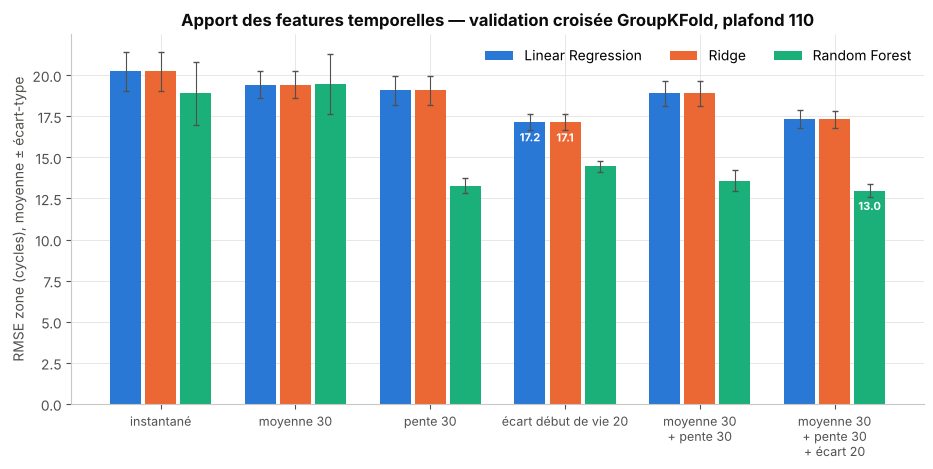

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.8))
specs = list(FEATURE_SPECS)
x = np.arange(len(specs))
width = 0.26
for i, model in enumerate(MODEL_NAMES):
    sub = feature_set_results[feature_set_results["modèle"] == model].set_index("features").loc[specs]
    bars = ax.bar(x + (i - 1) * width, sub["RMSE_zone"], width - 0.03, yerr=sub["RMSE_zone_std"],
                  color=MODEL_COLORS[model], label=MODEL_LABELS[model], capsize=2,
                  error_kw={"elinewidth": 0.8, "ecolor": INK_2})
    chosen = specs.index(SELECTED_SPEC[model])
    ax.annotate(f"{sub['RMSE_zone'].iloc[chosen]:.1f}", (x[chosen] + (i - 1) * width, sub["RMSE_zone"].iloc[chosen]),
                xytext=(0, -14), textcoords="offset points", ha="center", fontsize=8, color="white", fontweight="bold")
ax.set_xticks(x, [s.replace(" + ", "\n+ ") for s in specs], fontsize=9)
ax.set(ylabel="RMSE zone (cycles), moyenne ± écart-type",
       title="Apport des features temporelles — validation croisée GroupKFold, plafond 110")
ax.legend(ncols=3, loc="upper right")
save_figure(fig, "02_choix_features_temporelles")
plt.show()

**Lecture.** Les features temporelles apportent un **gain réel**, sur chacun des 5 folds, mais pas de la même façon selon le modèle :

- pour les **modèles linéaires**, c'est surtout l'**écart au début de vie** qui aide : il corrige le niveau de départ propre à chaque moteur, ce qu'une droite unique pour toute la flotte ne peut pas faire ;
- pour la **Random Forest**, c'est surtout la **pente** : l'arbre exploite la vitesse de dégradation de façon non linéaire (« si la pente dépasse un seuil, la panne est proche ») ;
- la **moyenne glissante seule** apporte peu : elle lisse le bruit sans ajouter d'information nouvelle.

Les jeux retenus diffèrent donc : l'**écart au début de vie seul** pour Linear Regression et Ridge (ajouter moyennes et pentes n'aide plus une droite), la **combinaison des trois familles** pour la Random Forest, qui sait exploiter des informations complémentaires.

## 9. Choix du plafond de RUL (par modèle)

**Objectif.** Le plafond optimal de la v1 (110) avait été choisi avec des features instantanées et un modèle linéaire. On le réajuste pour **chaque** modèle sur son jeu de features retenu. Critère : RMSE zone moyen.

In [12]:
t0 = time.time()
cap_rows, SELECTED_CAP = [], {}
for model in MODEL_NAMES:
    for cap in RUL_CAPS:
        per_fold = run_cv(model, SELECTED_SPEC[model], cap, START_PARAMS[model])
        cap_rows.append(summarize(per_fold, modèle=model, cap=cap))
cap_results = pd.DataFrame(cap_rows)
for model in MODEL_NAMES:
    sub = cap_results[cap_results["modèle"] == model]
    SELECTED_CAP[model] = int(sub.loc[sub["RMSE_zone"].idxmin(), "cap"])
print(f"Durée : {time.time() - t0:.0f} s — plafond retenu :", SELECTED_CAP)
cap_results.pivot(index="cap", columns="modèle", values="RMSE_zone")[list(MODEL_NAMES)].round(2)

Durée : 206 s — plafond retenu : {'LinearRegression': 110, 'Ridge': 110, 'RandomForest': 110}


modèle,LinearRegression,Ridge,RandomForest
cap,,,
90,19.14,19.14,15.75
100,17.48,17.47,13.68
110,17.16,17.15,12.98
120,17.92,17.91,13.44
125,18.59,18.57,13.94
130,19.37,19.35,14.53
140,21.13,21.11,15.87


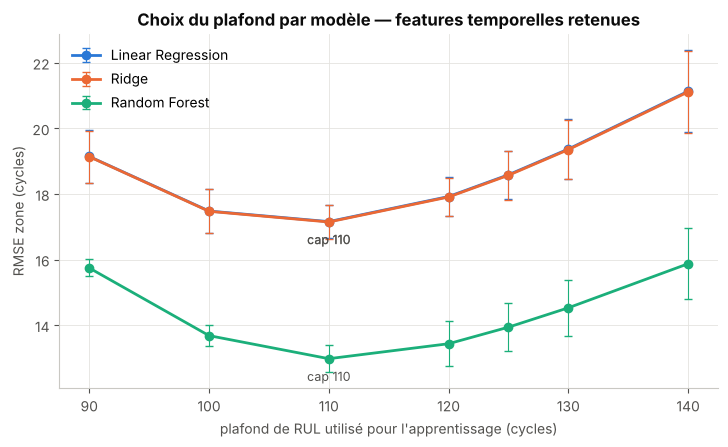

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for model in MODEL_NAMES:
    sub = cap_results[cap_results["modèle"] == model]
    ax.errorbar(sub["cap"], sub["RMSE_zone"], yerr=sub["RMSE_zone_std"], color=MODEL_COLORS[model], marker="o",
                markersize=6, capsize=3, elinewidth=0.8, label=MODEL_LABELS[model])
    best = sub.loc[sub["RMSE_zone"].idxmin()]
    ax.annotate(f"cap {int(best['cap'])}", (best["cap"], best["RMSE_zone"]), xytext=(0, -16),
                textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.set(xlabel="plafond de RUL utilisé pour l'apprentissage (cycles)", ylabel="RMSE zone (cycles)",
       title="Choix du plafond par modèle — features temporelles retenues")
ax.legend()
save_figure(fig, "03_choix_plafond_rul")
plt.show()

**Lecture.** Chaque courbe présente un minimum intérieur : un plafond trop bas empêche de prédire les RUL moyens, un plafond trop haut force le modèle à apprendre des RUL non observables. Le **même plafond** ressort pour les trois modèles, alors qu'ils utilisent des features différentes : ce choix dépend surtout des données (le moment où la dégradation devient visible dans les capteurs), pas du modèle. Pour la Random Forest, s'écarter de 10 cycles du plafond optimal coûte environ un demi-cycle de RMSE : le plafond reste un hyperparamètre important.

## 10. Optimisation des hyperparamètres

> **Hyperparamètre** : réglage choisi **avant** l'apprentissage (`alpha`, `min_samples_leaf`…), par opposition aux **paramètres** appris (coefficients, seuils des arbres). Il se règle en validation croisée, jamais sur le test.

- **Linear Regression** : aucun hyperparamètre.
- **Ridge** : grille de 15 valeurs d'`alpha` (0,001 à 10 000). Si plusieurs valeurs sont ex aequo à moins de 0,01 cycle, on retient la **plus régularisée** (même précision, coefficients plus stables).
- **Random Forest** : grille `min_samples_leaf` × `max_features` (6 combinaisons), 100 arbres.

In [14]:
t0 = time.time()
ridge_rows = []
for alpha in RIDGE_ALPHAS:
    per_fold = run_cv("Ridge", SELECTED_SPEC["Ridge"], SELECTED_CAP["Ridge"], {"alpha": float(alpha)})
    ridge_rows.append(summarize(per_fold, alpha=float(alpha)))
ridge_grid = pd.DataFrame(ridge_rows)
near_best = ridge_grid[ridge_grid["RMSE_zone"] <= ridge_grid["RMSE_zone"].min() + ALPHA_TOLERANCE]
BEST_ALPHA = float(near_best["alpha"].max())

rf_rows = []
for leaf in RF_GRID["min_samples_leaf"]:
    for max_feat in RF_GRID["max_features"]:
        params = {**RF_BASE_PARAMS, "min_samples_leaf": leaf, "max_features": max_feat}
        per_fold = run_cv("RandomForest", SELECTED_SPEC["RandomForest"], SELECTED_CAP["RandomForest"], params)
        rf_rows.append(summarize(per_fold, min_samples_leaf=leaf, max_features=max_feat))
rf_grid = pd.DataFrame(rf_rows)
best_rf = rf_grid.loc[rf_grid["RMSE_zone"].idxmin()]

SELECTED_PARAMS = {
    "LinearRegression": {},
    "Ridge": {"alpha": BEST_ALPHA},
    "RandomForest": {**RF_BASE_PARAMS, "min_samples_leaf": int(best_rf["min_samples_leaf"]),
                     "max_features": float(best_rf["max_features"])},
}
print(f"Durée : {time.time() - t0:.0f} s")
print("Ridge : alpha retenu =", BEST_ALPHA)
print("Random Forest : réglages retenus =", SELECTED_PARAMS["RandomForest"])
display(ridge_grid[["alpha", "RMSE_zone", "RMSE_zone_std"]].set_index("alpha").T.round(3))
rf_grid.pivot(index="min_samples_leaf", columns="max_features", values="RMSE_zone").round(3)

Durée : 234 s
Ridge : alpha retenu = 1000.0
Random Forest : réglages retenus = {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 0.33}


alpha,0.0010,0.0032,0.0100,0.0316,0.1000,0.3162,1.0000,3.1623,10.0000,31.6228,100.0000,316.2278,1000.0000,3162.2777,10000.0000
RMSE_zone,17.158,17.158,17.158,17.157,17.157,17.154,17.147,17.126,17.080,16.996,16.892,16.819,16.808,16.868,17.110
RMSE_zone_std,0.506,0.506,0.506,0.506,0.506,0.506,0.505,0.501,0.492,0.475,0.465,0.477,0.484,0.471,0.449


max_features,0.33,0.50
min_samples_leaf,,
5,12.900,12.961
10,12.980,13.090
20,13.233,13.285


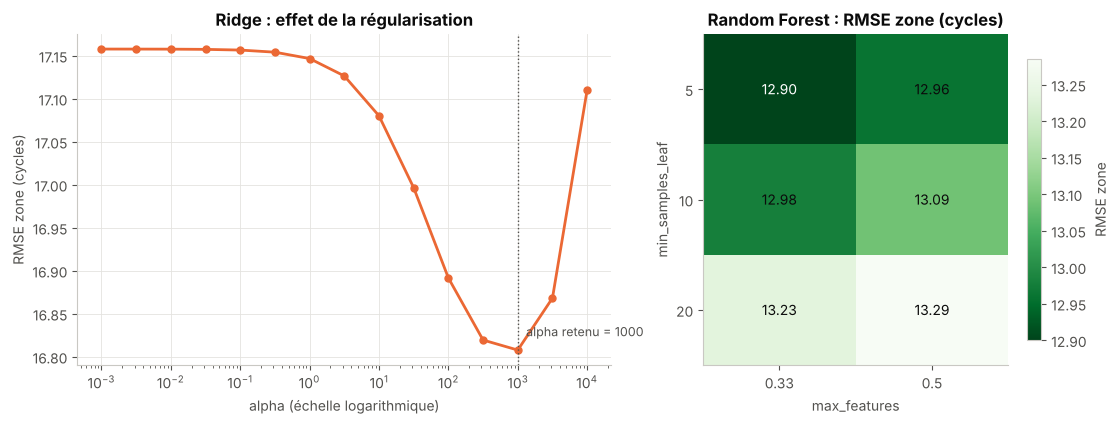

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
ax.plot(ridge_grid["alpha"], ridge_grid["RMSE_zone"], color=MODEL_COLORS["Ridge"], marker="o", markersize=5)
ax.axvline(BEST_ALPHA, color=INK_2, ls=":", lw=1)
ax.annotate(f"alpha retenu = {BEST_ALPHA:g}", (BEST_ALPHA, ridge_grid["RMSE_zone"].min()), xytext=(6, 10),
            textcoords="offset points", fontsize=9, color=INK_2)
ax.set_xscale("log")
ax.set(xlabel="alpha (échelle logarithmique)", ylabel="RMSE zone (cycles)", title="Ridge : effet de la régularisation")

ax = axes[1]
pivot = rf_grid.pivot(index="min_samples_leaf", columns="max_features", values="RMSE_zone")
im = ax.imshow(pivot.to_numpy(), cmap="Greens_r", aspect="auto")
for (i, j), value in np.ndenumerate(pivot.to_numpy()):
    ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=10,
            color="white" if value <= pivot.to_numpy().min() + 0.05 else INK)
ax.set_xticks(range(pivot.shape[1]), pivot.columns)
ax.set_yticks(range(pivot.shape[0]), pivot.index)
ax.grid(False)
ax.set(xlabel="max_features", ylabel="min_samples_leaf", title="Random Forest : RMSE zone (cycles)")
fig.colorbar(im, ax=ax, shrink=0.85, label="RMSE zone")
save_figure(fig, "04_hyperparametres")
plt.show()

**Lecture.**

- **Ridge** : contrairement à la v1, la régularisation apporte maintenant un léger gain. Les features d'écart au début de vie sont très corrélées aux mesures brutes ; sans pénalité, les coefficients de ces paires se compensent de façon instable. Au-delà de l'optimum, une pénalité trop forte écrase les coefficients et l'erreur remonte.
- **Random Forest** : les six combinaisons sont proches, le modèle est **robuste** à ses réglages. Des feuilles plus petites (`min_samples_leaf` = 5) donnent un léger avantage : avec plus de 13 000 lignes d'apprentissage par fold, le modèle peut se permettre des règles plus fines sans sur-apprendre.

## 11. Sélection du modèle (validation croisée, sans le test)

**Objectif.** Comparer les trois modèles **optimisés**, chacun avec ses propres features, plafond et hyperparamètres, sur les mêmes 5 folds.

**Règle de sélection (déclarée).** On retient le modèle au meilleur RMSE zone moyen. S'il ne bat pas le deuxième **sur chacun des 5 folds**, les deux sont jugés équivalents et l'on retient le plus simple (ordre de simplicité : Linear Regression < Ridge < Random Forest).

Cette sélection n'utilise **que** les 80 moteurs d'analyse. Elle est ensuite vérifiée sur les 20 moteurs de validation (section 14), puis figée et enregistrée **avant** toute lecture du test (section 16).

In [16]:
FINAL_CV = {m: run_cv(m, SELECTED_SPEC[m], SELECTED_CAP[m], SELECTED_PARAMS[m]) for m in MODEL_NAMES}
model_comparison = pd.DataFrame([
    summarize(FINAL_CV[m], modèle=MODEL_LABELS[m], features=SELECTED_SPEC[m], cap=SELECTED_CAP[m],
              hyperparamètres=params_key(SELECTED_PARAMS[m]))
    for m in MODEL_NAMES]).set_index("modèle")

ranking = sorted(MODEL_NAMES, key=lambda m: FINAL_CV[m]["RMSE_zone"].mean())
leader, runner_up = ranking[0], ranking[1]
LEADER_GAIN = paired_gain(FINAL_CV[runner_up], FINAL_CV[leader])
if LEADER_GAIN["folds_improved"] >= REQUIRED_FOLDS_IMPROVED:
    SELECTED_MODEL = leader
else:   # équivalents : on garde le plus simple des deux
    SELECTED_MODEL = min(leader, runner_up, key=MODEL_NAMES.index)

pairwise = pd.DataFrame([{"comparaison": f"{MODEL_LABELS[a]} vs {MODEL_LABELS[b]}",
                          **paired_gain(FINAL_CV[b], FINAL_CV[a])}
                         for a in MODEL_NAMES for b in MODEL_NAMES if a != b and ranking.index(a) < ranking.index(b)])
print(f"Classement CV : {[MODEL_LABELS[m] for m in ranking]}")
print(f"{MODEL_LABELS[leader]} bat {MODEL_LABELS[runner_up]} sur {LEADER_GAIN['folds_improved']}/{N_SPLITS} folds "
      f"(gain moyen {LEADER_GAIN['gain_mean']:.2f} cycles) -> modèle retenu : {MODEL_LABELS[SELECTED_MODEL]}")
display(model_comparison[["features", "cap", "hyperparamètres", "MAE_zone", "RMSE_zone", "RMSE_zone_std", "R2_zone",
                          "RMSE_global", "R2_global"]].round(3))
pairwise.set_index("comparaison").round(3)

Classement CV : ['Random Forest', 'Ridge', 'Linear Regression']
Random Forest bat Ridge sur 5/5 folds (gain moyen 3.91 cycles) -> modèle retenu : Random Forest


,features,cap,hyperparamètres,MAE_zone,RMSE_zone,RMSE_zone_std,R2_zone,RMSE_global,R2_global
modèle,,,,,,,,,
Linear Regression,écart début de vie 20,110,{},14.004,17.158,0.506,0.784,55.857,0.356
Ridge,écart début de vie 20,110,"{""alpha"": 1000.0}",13.805,16.808,0.484,0.793,55.595,0.362
Random Forest,moyenne 30 + pente 30 + écart 20,110,"{""max_features"": 0.33, ""min_samples_leaf"": 5, ...",9.623,12.900,0.473,0.878,54.292,0.392


,gain_mean,gain_min,folds_improved,n_folds
comparaison,,,,
Ridge vs Linear Regression,0.350,-0.113,4,5
Random Forest vs Linear Regression,4.258,3.624,5,5
Random Forest vs Ridge,3.908,3.147,5,5


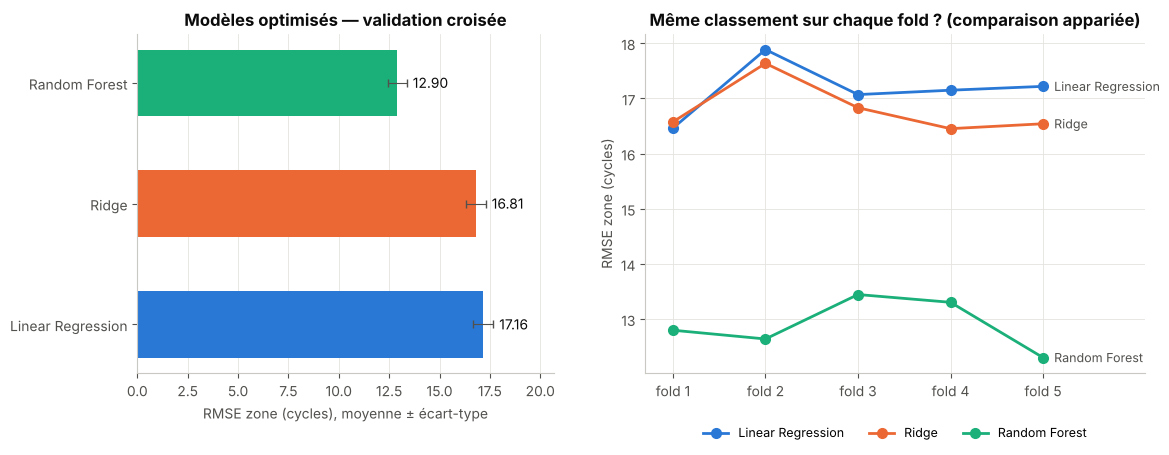

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
order = ranking[::-1]
values = [FINAL_CV[m]["RMSE_zone"].mean() for m in order]
errors = [FINAL_CV[m]["RMSE_zone"].std(ddof=1) for m in order]
ax.barh([MODEL_LABELS[m] for m in order], values, xerr=errors, color=[MODEL_COLORS[m] for m in order],
        height=0.55, capsize=3, error_kw={"elinewidth": 0.8, "ecolor": INK_2})
for i, (v, e) in enumerate(zip(values, errors)):
    ax.text(v + e + 0.3, i, f"{v:.2f}", va="center", color=INK, fontsize=10)
ax.set(xlabel="RMSE zone (cycles), moyenne ± écart-type", title="Modèles optimisés — validation croisée")
ax.set_xlim(0, max(values) + max(errors) + 3)
ax.grid(axis="y", visible=False)

ax = axes[1]
folds = np.arange(1, N_SPLITS + 1)
for m in MODEL_NAMES:
    ax.plot(folds, FINAL_CV[m]["RMSE_zone"], color=MODEL_COLORS[m], marker="o", markersize=7, label=MODEL_LABELS[m])
    ax.annotate(MODEL_LABELS[m], (folds[-1], FINAL_CV[m]["RMSE_zone"].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK_2)
ax.set_xticks(folds, [f"fold {f}" for f in folds])
ax.set_xlim(0.7, N_SPLITS + 1.1)
ax.set(ylabel="RMSE zone (cycles)", title="Même classement sur chaque fold ? (comparaison appariée)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncols=3, fontsize=9)
save_figure(fig, "05_selection_modele_cv")
plt.show()

**Lecture.** Le graphique de droite montre les **5 mêmes groupes de moteurs** évalués par les trois modèles : quand une courbe est sous les autres sur chaque fold, l'écart ne vient pas du hasard du découpage. Le modèle retenu est affiché au-dessus du tableau, avec le nombre de folds gagnés contre le deuxième.

## 12. Ablations demandées par l'EDA (modèle retenu)

**Objectif.** Tester sur le modèle retenu les décisions laissées « à valider » par l'EDA (README §8.3, décisions 8 à 10). Chaque variante modifie les **17 features de base** ; les features temporelles sont recalculées à partir des capteurs restants. Une variante n'est adoptée que si elle gagne sur les 5 folds.

> **Ablation** : expérience qui retire ou ajoute un élément pour mesurer son effet réel. C'est la seule façon de **confirmer** une hypothèse de l'EDA (« observation ≠ preuve »).

In [18]:
t0 = time.time()
redundant_dropped = [f for group in feature_groups["redundant_groups"] for f in group[1:]]
ablation_bases = {
    "Référence (17 features de base)": CANDIDATE_FEATURES,
    "+ cycle": CANDIDATE_FEATURES + ["cycle"],
    "- sensor_6": [f for f in CANDIDATE_FEATURES if f != "sensor_6"],
    "- setting_1, setting_2": [f for f in CANDIDATE_FEATURES if f not in ("setting_1", "setting_2")],
    "- sensor_9, sensor_14": [f for f in CANDIDATE_FEATURES if f not in feature_groups["heterogeneous_trend"]],
    f"1 capteur par groupe redondant (- {', '.join(redundant_dropped)})":
        [f for f in CANDIDATE_FEATURES if f not in redundant_dropped],
}
reference = FINAL_CV[SELECTED_MODEL]
ablation_rows, adoptable = [], {}
for label, base in ablation_bases.items():
    per_fold = run_cv(SELECTED_MODEL, SELECTED_SPEC[SELECTED_MODEL], SELECTED_CAP[SELECTED_MODEL],
                      SELECTED_PARAMS[SELECTED_MODEL], base=tuple(base))
    gain = paired_gain(reference, per_fold)
    ablation_rows.append(summarize(per_fold, variante=label, n_features_base=len(base),
                                   gain=gain["gain_mean"], folds_gagnés=gain["folds_improved"]))
    if label != "Référence (17 features de base)" and gain["folds_improved"] >= REQUIRED_FOLDS_IMPROVED:
        adoptable[label] = per_fold["RMSE_zone"].mean()
ablation_results = pd.DataFrame(ablation_rows).set_index("variante")
ADOPTED_ABLATION = min(adoptable, key=adoptable.get) if adoptable else None
SELECTED_BASE = ablation_bases[ADOPTED_ABLATION] if ADOPTED_ABLATION else CANDIDATE_FEATURES
print(f"Durée : {time.time() - t0:.0f} s — variante adoptée : {ADOPTED_ABLATION or 'aucune (référence conservée)'}")
ablation_results[["n_features_base", "RMSE_zone", "RMSE_zone_std", "gain", "folds_gagnés"]].round(3)

Durée : 169 s — variante adoptée : aucune (référence conservée)


,n_features_base,RMSE_zone,RMSE_zone_std,gain,folds_gagnés
variante,,,,,
Référence (17 features de base),17,12.900,0.473,0.000,0
+ cycle,18,12.494,0.339,0.406,4
- sensor_6,16,12.869,0.400,0.031,2
"- setting_1, setting_2",15,12.940,0.434,-0.040,1
"- sensor_9, sensor_14",15,14.484,0.566,-1.584,0
"1 capteur par groupe redondant (- sensor_14, sensor_13, sensor_12)",14,13.451,0.479,-0.551,0


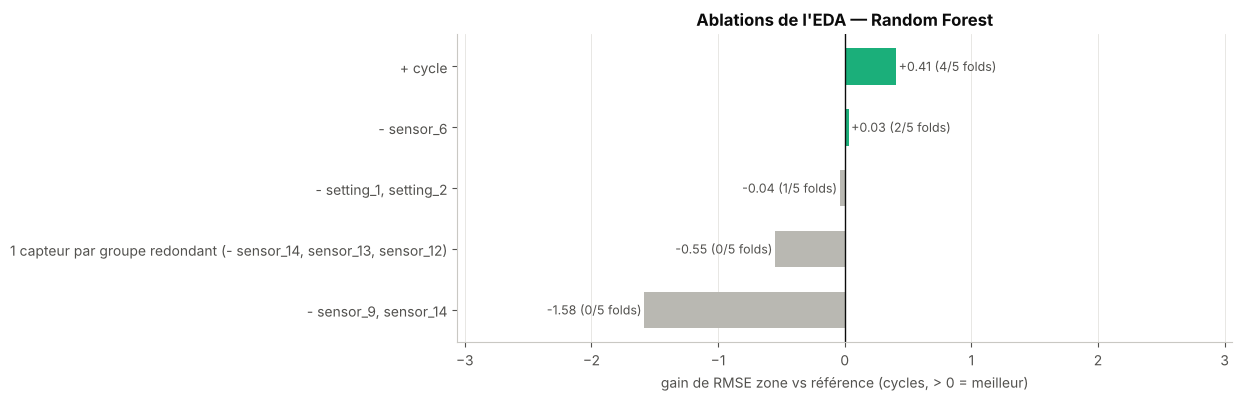

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_df = ablation_results.drop(index="Référence (17 features de base)").sort_values("gain")
ax.barh(plot_df.index, plot_df["gain"], color=[MODEL_COLORS[SELECTED_MODEL] if g > 0 else "#b9b8b2" for g in plot_df["gain"]],
        height=0.6)
for i, (g, n) in enumerate(zip(plot_df["gain"], plot_df["folds_gagnés"])):
    ax.text(g + (0.02 if g >= 0 else -0.02), i, f"{g:+.2f} ({n}/{N_SPLITS} folds)", va="center",
            ha="left" if g >= 0 else "right", fontsize=9, color=INK_2)
ax.axvline(0, color=INK, lw=1)
lim = plot_df["gain"].abs().max() * 1.9 + 0.05
ax.set_xlim(-lim, lim)
ax.grid(axis="y", visible=False)
ax.set(xlabel="gain de RMSE zone vs référence (cycles, > 0 = meilleur)",
       title=f"Ablations de l'EDA — {MODEL_LABELS[SELECTED_MODEL]}")
save_figure(fig, "06_ablations")
plt.show()

**Lecture.** Les étiquettes indiquent, pour chaque variante, le gain moyen et le nombre de folds sur lesquels elle bat la référence. Une variante n'est adoptée que si elle gagne sur les 5 folds ; la conclusion (section 19) précise le résultat obtenu. Ces conclusions valent pour le modèle retenu : un autre modèle pourrait réagir différemment.

## 13. Gestion des prédictions RUL négatives

**Objectif.** Un modèle linéaire n'a aucune contrainte de signe : près de la panne, il peut prédire un RUL **négatif**. Une Random Forest, elle, ne le peut pas : sa prédiction est une **moyenne de RUL d'apprentissage**, tous ≥ 0. On mesure le phénomène sans post-traitement, puis on applique la règle **« toute prédiction < 0 devient 0 »**, sans paramètre appris, donc sans risque de fuite.

In [20]:
negative_rows = {}
for m in MODEL_NAMES:
    _, oof_raw = run_cv(m, SELECTED_SPEC[m], SELECTED_CAP[m], SELECTED_PARAMS[m], clip=False, return_oof=True)
    y_true = analysis_df["RUL"].to_numpy()
    zone = y_true <= EVAL_HORIZON
    negative_rows[MODEL_LABELS[m]] = {
        "prédictions négatives": int((oof_raw < 0).sum()),
        "part": (oof_raw < 0).mean(),
        "minimum": oof_raw.min(),
        "RMSE zone sans clipping": regression_metrics(y_true[zone], oof_raw[zone])["RMSE"],
        "RMSE zone avec clipping": regression_metrics(y_true[zone], clip_negative(oof_raw)[zone])["RMSE"],
    }
negative_summary = pd.DataFrame(negative_rows).T
N_NEGATIVE = negative_summary["prédictions négatives"].astype(int).to_dict()
negative_summary.round(4)

,prédictions négatives,part,minimum,RMSE zone sans clipping,RMSE zone avec clipping
Linear Regression,565.0,0.0341,-87.9169,17.9213,17.1637
Ridge,530.0,0.0320,-88.8278,17.5118,16.8133
Random Forest,0.0,0.0000,1.1101,12.9069,12.9069


**Lecture.** Les prédictions négatives ne concernent que les modèles linéaires et se concentrent sur les derniers cycles avant la panne ; la Random Forest n'en produit aucune. Le clipping ne peut que réduire l'erreur (le RUL réel est ≥ 0) et garantit qu'un RUL affiché par l'API ou le dashboard n'est jamais négatif. Il est appliqué de la même façon en validation et sur le test.

## 14. Vérification sur les 20 moteurs de validation figés

**Objectif.** Toutes les décisions ont été prises sur les 80 moteurs d'analyse. On entraîne maintenant chaque modèle optimisé sur ces 80 moteurs, puis on l'évalue **une fois** sur les 20 moteurs de validation, jamais utilisés jusqu'ici.

Si le classement des modèles ou leur niveau d'erreur changeait fortement, ce serait un signal d'alerte (sélection trop ajustée aux folds, split défavorable). La sélection **n'est pas modifiée** à partir de ces résultats : ils servent de contrôle.

In [21]:
def fit_config(model, df_name, base=None):
    # Entraîne un modèle optimisé (features, plafond, hyperparamètres retenus) sur un jeu étiqueté.
    base = tuple(SELECTED_BASE if base is None else base)
    df_feat, feats = get_feature_set(df_name, SELECTED_SPEC[model], base)
    pipe = make_model(model, random_state=RANDOM_STATE, **SELECTED_PARAMS[model])
    return pipe.fit(df_feat[feats], cap_target(df_feat["RUL"], SELECTED_CAP[model])), feats


validation_models, validation_pred = {}, {}
for m in MODEL_NAMES:
    validation_models[m], feats = fit_config(m, "analysis")
    df_val, _ = get_feature_set("validation", SELECTED_SPEC[m], tuple(SELECTED_BASE))
    validation_pred[m] = clip_negative(validation_models[m].predict(df_val[feats]))

y_validation = validation_df["RUL"].to_numpy()
validation_metrics = {m: evaluate_predictions(y_validation, validation_pred[m], EVAL_HORIZON) for m in MODEL_NAMES}
val_table = pd.DataFrame({
    (MODEL_LABELS[m], "CV 80 moteurs"): FINAL_CV[m].mean() for m in MODEL_NAMES} | {
    (MODEL_LABELS[m], "validation 20 moteurs"): pd.Series(validation_metrics[m]) for m in MODEL_NAMES}).T
val_table = val_table[["MAE_zone", "RMSE_zone", "R2_zone", "MAE_global", "RMSE_global", "R2_global"]].sort_index()
VALIDATION_RANKING = sorted(MODEL_NAMES, key=lambda m: validation_metrics[m]["RMSE_zone"])
SAME_RANKING = VALIDATION_RANKING == ranking
print("Classement sur la validation figée :", [MODEL_LABELS[m] for m in VALIDATION_RANKING],
      "— identique à la validation croisée :", SAME_RANKING)
val_table.round(3)

Classement sur la validation figée : ['Random Forest', 'Ridge', 'Linear Regression'] — identique à la validation croisée : True


MAE_zone  RMSE_zone  R2_zone  \
Linear Regression CV 80 moteurs            14.004     17.158    0.784   
                  validation 20 moteurs    13.471     16.460    0.802   
Random Forest     CV 80 moteurs             9.623     12.900    0.878   
                  validation 20 moteurs     8.378     11.414    0.905   
Ridge             CV 80 moteurs            13.805     16.808    0.793   
                  validation 20 moteurs    13.378     16.309    0.805   

                                         MAE_global  RMSE_global  R2_global  
Linear Regression CV 80 moteurs              37.809       55.857      0.356  
                  validation 20 moteurs      34.838       49.468      0.432  
Random Forest     CV 80 moteurs              34.438       54.292      0.392  
                  validation 20 moteurs      31.018       48.061      0.464  
Ridge             CV 80 moteurs              37.608       55.595      0.362  
                  validation 20 moteurs      34.618       49.154      0.439

In [22]:
validation_results = validation_df[["unit_id", "cycle", "RUL"]].copy()
for m in MODEL_NAMES:
    validation_results[f"pred_{m}"] = validation_pred[m]
    validation_results[f"erreur_{m}"] = validation_pred[m] - validation_results["RUL"]   # > 0 : prédiction tardive

band_tables = {MODEL_LABELS[m]: rul_band_table(validation_results["RUL"], validation_results[f"erreur_{m}"], RUL_BANDS)
               for m in MODEL_NAMES}
validation_bands = pd.concat(band_tables, axis=1)
validation_bands.round(2)

Linear Regression                            Ridge                \
                   lignes    MAE   RMSE biais_moyen lignes    MAE   RMSE   
tranche                                                                    
0–25                  520  11.42  14.12        5.94    520  11.45  14.19   
25–75                1000  14.50  17.50       12.33   1000  14.58  17.47   
75–127               1040  13.50  16.51       -9.44   1040  13.18  16.14   
> 127                1510  71.06  78.34      -71.06   1510  70.63  77.85   

                    Random Forest                            
        biais_moyen        lignes    MAE   RMSE biais_moyen  
tranche                                                      
0–25           6.36           520   2.85   3.68        1.99  
25–75         12.78          1000   8.53  11.83        5.28  
75–127        -9.14          1040  11.00  13.39       -4.76  
> 127        -70.63          1510  69.40  77.49      -69.40

In [23]:
zone_val = validation_results[validation_results["RUL"] <= EVAL_HORIZON]
per_engine = pd.DataFrame({
    MODEL_LABELS[m]: zone_val.groupby("unit_id")[f"erreur_{m}"].apply(lambda e: float(np.sqrt((e ** 2).mean())))
    for m in MODEL_NAMES})
per_engine["longueur_vie"] = validation_df.groupby("unit_id")["cycle"].max()
per_engine = per_engine.sort_values(MODEL_LABELS[SELECTED_MODEL])
ENGINES_IMPROVED = int((per_engine[MODEL_LABELS[SELECTED_MODEL]] < per_engine[[MODEL_LABELS[m] for m in MODEL_NAMES
                                                                               if m != SELECTED_MODEL]].min(axis=1)).sum())
print(f"Moteurs de validation où le modèle retenu a la plus faible erreur : {ENGINES_IMPROVED}/{len(per_engine)}")
per_engine.round(2).T

Moteurs de validation où le modèle retenu a la plus faible erreur : 20/20


unit_id,34,32,31,40,11,78,71,54,19,81,91,5,46,1,13,74,23,84,45,77
Linear Regression,15.12,16.92,12.02,17.92,10.72,10.70,15.36,13.73,17.99,15.07,21.85,13.84,14.11,12.80,19.38,18.82,16.73,18.84,17.99,22.65
Ridge,15.08,16.39,10.87,17.02,10.56,10.84,15.68,13.04,19.25,15.50,22.02,14.37,12.33,13.61,20.26,18.64,17.59,18.64,16.97,20.71
Random Forest,6.92,7.29,7.30,7.36,7.65,7.85,8.02,8.69,8.98,10.10,10.17,10.45,11.45,12.30,13.21,13.65,14.25,15.75,16.58,19.29
longueur_vie,195.00,191.00,234.00,188.00,240.00,231.00,208.00,257.00,158.00,240.00,135.00,269.00,256.00,192.00,163.00,166.00,168.00,267.00,158.00,154.00


**Lecture.** Le tableau compare, pour chaque modèle, la validation croisée et la validation figée ; le classement obtenu sur les 20 moteurs est affiché au-dessus. Le tableau par tranche de RUL distingue deux types d'erreurs :

- **proche panne** (0–25, 25–75) : un biais **positif** signifie que le modèle annonce **plus** de vie qu'il n'en reste, la direction dangereuse ;
- **moteur sain** (> 127) : un biais très négatif est l'effet **voulu** du plafond (prédiction prudente, sans conséquence opérationnelle).

## 15. Graphiques d'analyse

**Objectif.** Visualiser, sur les 20 moteurs de validation :

1. prédiction contre réel pour les trois modèles ;
2. distribution des erreurs par tranche de RUL ;
3. trajectoires de RUL prédites pour quatre moteurs ;
4. ce sur quoi s'appuie la Random Forest (importance par permutation).

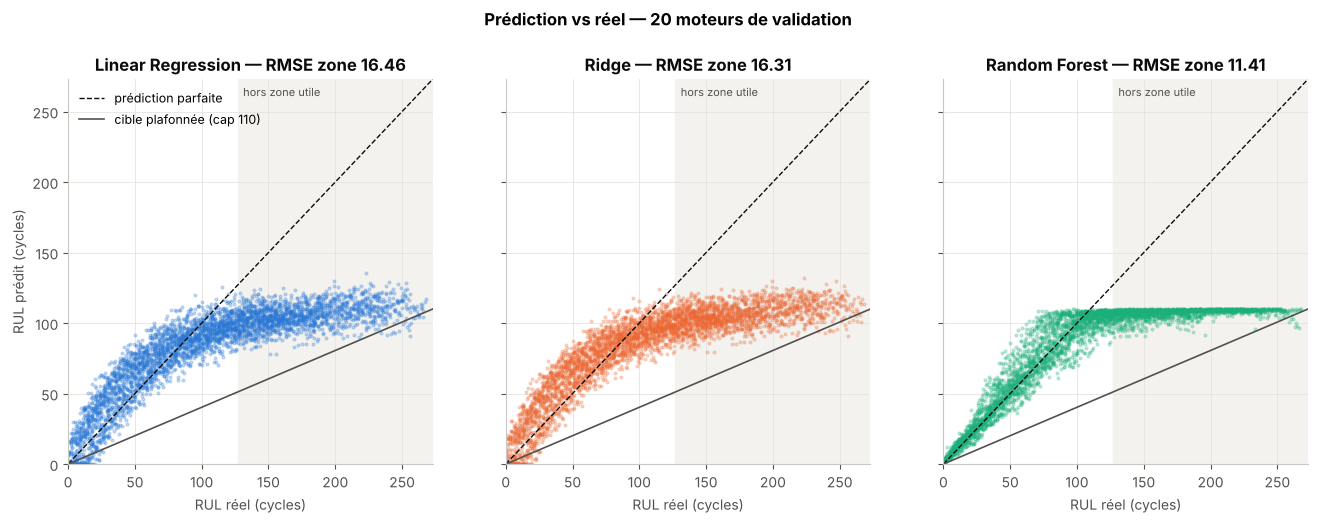

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lim = [0, validation_results["RUL"].max() + 5]
for ax, m in zip(axes, MODEL_NAMES):
    ax.scatter(validation_results["RUL"], validation_results[f"pred_{m}"], s=4, alpha=0.25, color=MODEL_COLORS[m],
               rasterized=True)
    ax.plot(lim, lim, color=INK, ls="--", lw=1, label="prédiction parfaite")
    ax.plot(lim, np.minimum(lim, SELECTED_CAP[m]), color=INK_2, lw=1.2, label=f"cible plafonnée (cap {SELECTED_CAP[m]})")
    ax.axvspan(EVAL_HORIZON, lim[1], color="#f3f2ef", zorder=0)
    met = validation_metrics[m]
    ax.set(title=f"{MODEL_LABELS[m]} — RMSE zone {met['RMSE_zone']:.2f}", xlabel="RUL réel (cycles)",
           xlim=lim, ylim=[0, lim[1]])
    ax.text(EVAL_HORIZON + 4, lim[1] - 12, "hors zone utile", fontsize=8, color=INK_2)
axes[0].set_ylabel("RUL prédit (cycles)")
axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Prédiction vs réel — 20 moteurs de validation", y=1.02, fontweight="bold")
save_figure(fig, "07_validation_pred_vs_reel")
plt.show()

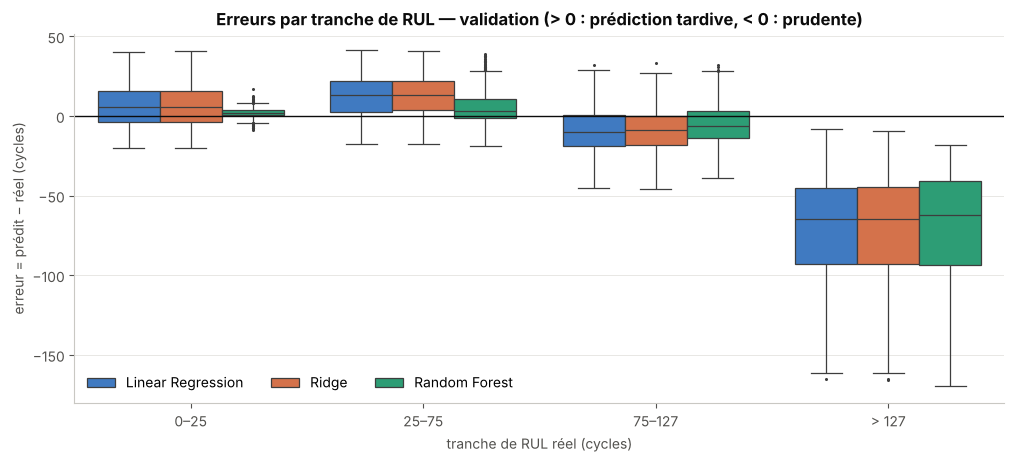

In [25]:
long = validation_results.melt(id_vars=["unit_id", "cycle", "RUL"], value_vars=[f"erreur_{m}" for m in MODEL_NAMES],
                               var_name="modèle", value_name="erreur")
long["modèle"] = long["modèle"].str.replace("erreur_", "").map(MODEL_LABELS)
band_labels = list(band_tables[MODEL_LABELS[SELECTED_MODEL]].index)
long["tranche"] = pd.cut(long["RUL"], bins=RUL_BANDS, labels=band_labels, include_lowest=True)

fig, ax = plt.subplots(figsize=(12, 4.8))
sns.boxplot(data=long, x="tranche", y="erreur", hue="modèle", ax=ax, fliersize=1.2, linewidth=0.9,
            palette={MODEL_LABELS[m]: MODEL_COLORS[m] for m in MODEL_NAMES},
            hue_order=[MODEL_LABELS[m] for m in MODEL_NAMES])
ax.axhline(0, color=INK, lw=1)
ax.set(xlabel="tranche de RUL réel (cycles)", ylabel="erreur = prédit − réel (cycles)",
       title="Erreurs par tranche de RUL — validation (> 0 : prédiction tardive, < 0 : prudente)")
ax.legend(title=None, ncols=3, loc="lower left")
save_figure(fig, "08_erreurs_par_tranche_rul")
plt.show()

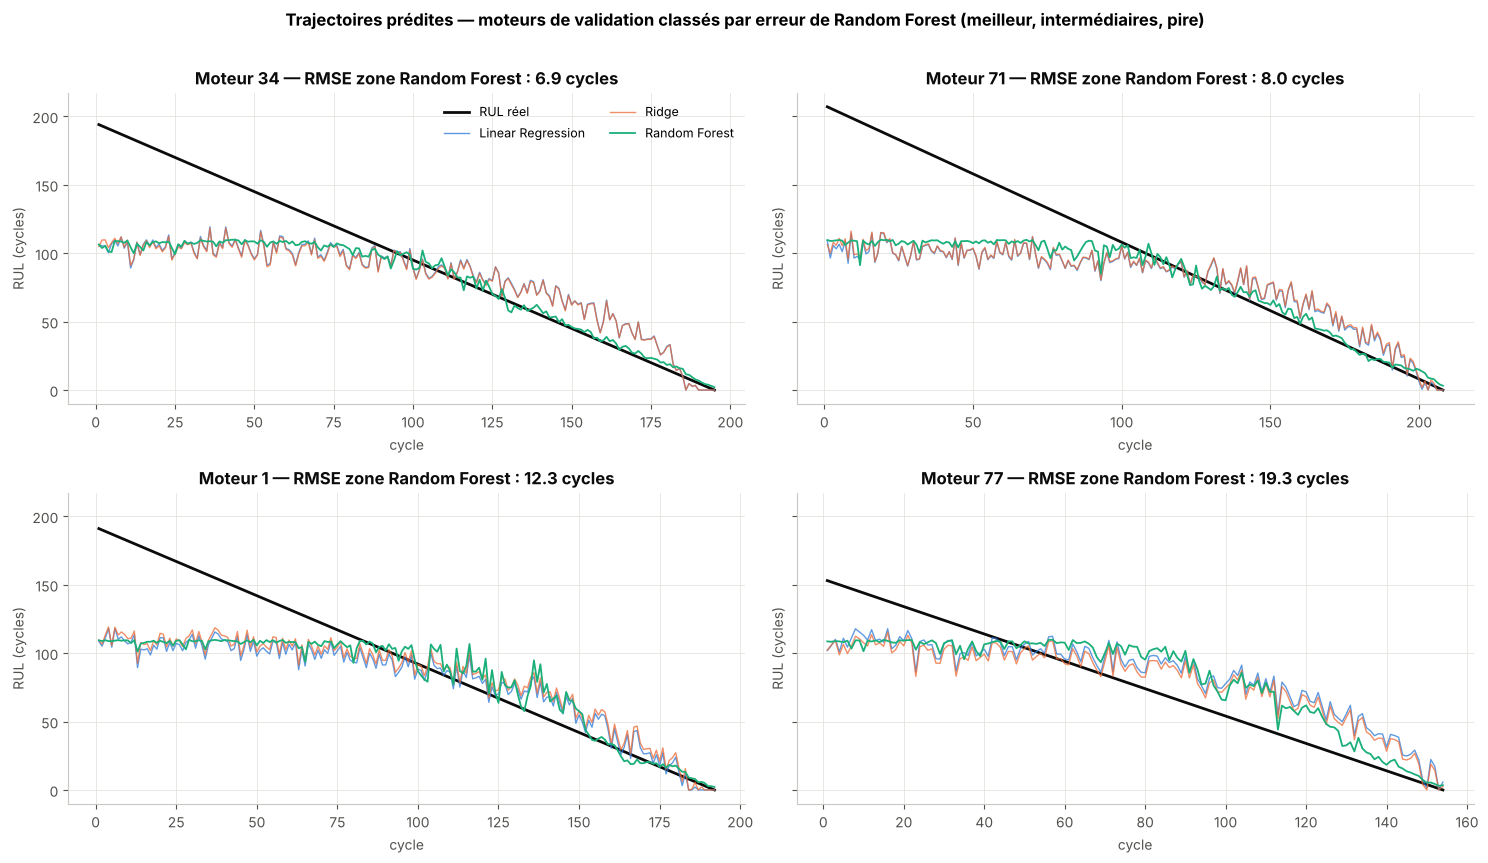

In [26]:
ranked = per_engine.index.tolist()
engines_to_plot = [ranked[0], ranked[len(ranked) // 3], ranked[2 * len(ranked) // 3], ranked[-1]]
fig, axes = plt.subplots(2, 2, figsize=(15, 8.5), sharey=True)
for ax, unit in zip(axes.ravel(), engines_to_plot):
    eng = validation_results[validation_results["unit_id"] == unit]
    ax.plot(eng["cycle"], eng["RUL"], color=INK, lw=2, label="RUL réel")
    for m in MODEL_NAMES:
        ax.plot(eng["cycle"], eng[f"pred_{m}"], color=MODEL_COLORS[m], lw=1.3 if m == SELECTED_MODEL else 1,
                alpha=1 if m == SELECTED_MODEL else 0.75, label=MODEL_LABELS[m])
    ax.set(title=f"Moteur {unit} — RMSE zone {MODEL_LABELS[SELECTED_MODEL]} : "
                 f"{per_engine.loc[unit, MODEL_LABELS[SELECTED_MODEL]]:.1f} cycles", xlabel="cycle", ylabel="RUL (cycles)")
axes[0, 0].legend(fontsize=9, ncols=2)
fig.suptitle(f"Trajectoires prédites — moteurs de validation classés par erreur de {MODEL_LABELS[SELECTED_MODEL]} "
             "(meilleur, intermédiaires, pire)", y=1.01, fontweight="bold")
fig.tight_layout()
save_figure(fig, "09_trajectoires_validation")
plt.show()

### 15.1 Sur quoi s'appuie la Random Forest ?

> **Importance par permutation.** On mélange au hasard les valeurs d'une feature dans les données de validation et l'on mesure **de combien l'erreur augmente**. Si le modèle dépend de cette feature, l'erreur monte beaucoup ; sinon, elle ne bouge pas. Contrairement à l'importance « interne » des arbres, cette mesure est calculée sur des moteurs jamais vus, en cycles de RMSE.

Le calcul est fait sur la zone utile des 20 moteurs de validation, avec le modèle entraîné sur les 80 moteurs d'analyse. Il sert à **interpréter**, pas à sélectionner.

Durée : 13 s — feature la plus importante : sensor_3_mean30


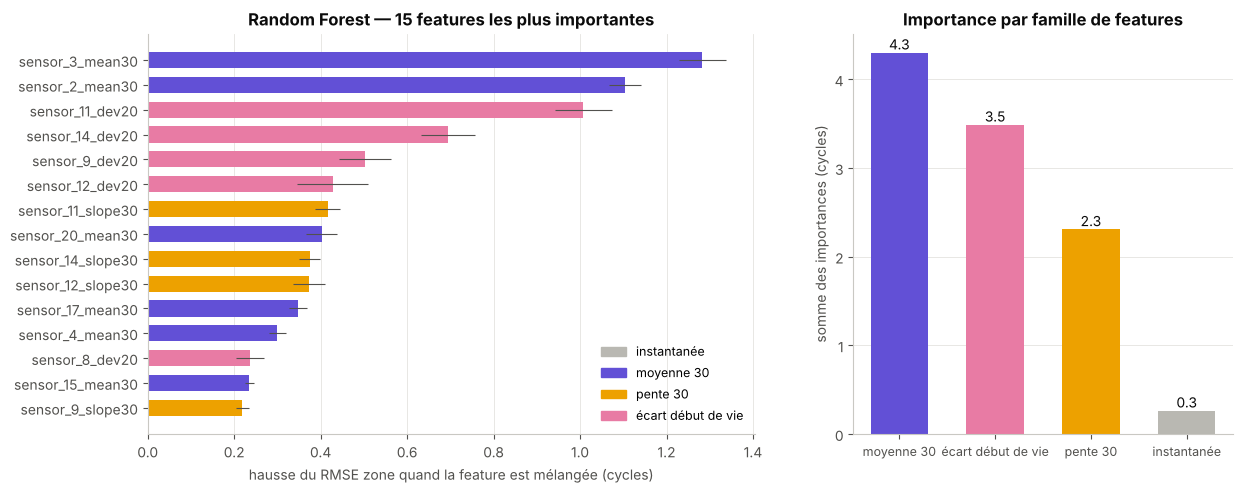

In [27]:
t0 = time.time()
df_val_rf, rf_feats = get_feature_set("validation", SELECTED_SPEC["RandomForest"], tuple(SELECTED_BASE))
zone_mask = df_val_rf["RUL"].to_numpy() <= EVAL_HORIZON
perm = permutation_importance(validation_models["RandomForest"], df_val_rf.loc[zone_mask, rf_feats],
                              df_val_rf.loc[zone_mask, "RUL"], scoring="neg_root_mean_squared_error",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({"feature": rf_feats, "importance": perm.importances_mean,
                           "std": perm.importances_std}).sort_values("importance", ascending=False)
FAMILY_NAMES = {"mean": "moyenne 30", "slope": "pente 30", "dev": "écart début de vie"}
importance["famille"] = importance["feature"].map(
    lambda f: next((name for key, name in FAMILY_NAMES.items() if f"_{key}" in f), "instantanée"))
family_importance = importance.groupby("famille")["importance"].sum().sort_values(ascending=False)
TOP_FEATURE = importance.iloc[0]["feature"]
print(f"Durée : {time.time() - t0:.0f} s — feature la plus importante : {TOP_FEATURE}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.6, 1]})
# Couleurs distinctes de celles des modèles : ici la couleur code la FAMILLE de feature, pas le modèle.
family_colors = {"instantanée": "#b9b8b2", "moyenne 30": "#6250d6", "pente 30": "#eda100",
                 "écart début de vie": "#e87ba4"}
top = importance.head(15)[::-1]
axes[0].barh(top["feature"], top["importance"], xerr=top["std"], color=top["famille"].map(family_colors), height=0.65,
             error_kw={"elinewidth": 0.8, "ecolor": INK_2})
axes[0].set(xlabel="hausse du RMSE zone quand la feature est mélangée (cycles)",
            title="Random Forest — 15 features les plus importantes")
axes[0].grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in family_colors.values()]
axes[0].legend(handles, family_colors.keys(), loc="lower right", fontsize=9)
axes[1].bar(family_importance.index, family_importance.values, color=[family_colors[f] for f in family_importance.index],
            width=0.6)
for i, v in enumerate(family_importance.values):
    axes[1].text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=10, color=INK)
axes[1].set(ylabel="somme des importances (cycles)", title="Importance par famille de features")
axes[1].tick_params(axis="x", labelsize=9)
axes[1].grid(axis="x", visible=False)
save_figure(fig, "10_importance_permutation_rf")
plt.show()

**Lecture.** L'importance par famille montre quel type d'information porte la prédiction de la Random Forest. Attention : quand deux features sont redondantes (deux capteurs corrélés, ou une mesure et sa moyenne), le modèle peut s'appuyer sur l'une ou l'autre ; mélanger une seule d'entre elles fait alors peu monter l'erreur. Une importance faible ne prouve donc pas qu'une feature est inutile, et une importance n'est pas une causalité physique.

## 16. Entraînement final, sauvegarde, rechargement et gel du pipeline

**Objectif.** **Figer** toutes les décisions avant de toucher au test.

1. Chaque modèle optimisé est réentraîné sur les **100 moteurs du train** (80 + 20) : les choix sont figés, on exploite simplement toutes les données étiquetées.
2. Le **modèle retenu** est sérialisé avec `joblib`, avec sa configuration complète (features, plafond, hyperparamètres). Les fichiers `.joblib` ne sont pas versionnés (`.gitignore`).
3. La sélection est écrite dans `model_selection.json` **avant** la lecture du test, puis le pipeline est gelé (`GroundTruthGuard.freeze()`).

> **Sérialisation.** Enregistrer le pipeline entraîné dans un fichier pour le recharger plus tard (API FastAPI en S6) sans réentraîner. Le fichier ne contient que des objets scikit-learn ; les features temporelles se recalculent avec `ml.src.features.build_feature_set` et la spécification enregistrée.

In [28]:
t0 = time.time()
final_models, final_features = {}, {}
for m in MODEL_NAMES:
    final_models[m], final_features[m] = fit_config(m, "full_train")

FINAL_CONFIG = {
    "model": SELECTED_MODEL,
    "hyperparameters": SELECTED_PARAMS[SELECTED_MODEL],
    "rul_cap": SELECTED_CAP[SELECTED_MODEL],
    "feature_set": SELECTED_SPEC[SELECTED_MODEL],
    "feature_spec": FEATURE_SPECS[SELECTED_SPEC[SELECTED_MODEL]],
    "base_features": list(SELECTED_BASE),
    "features": final_features[SELECTED_MODEL],
    "prediction_postprocessing": "clip(prediction, 0, +inf)",
    "trained_on": "100 moteurs de train_FD001 (80 analyse + 20 validation)",
    "selection": f"RMSE zone (RUL réel <= {EVAL_HORIZON}) en GroupKFold({N_SPLITS}) sur 80 moteurs, "
                 f"règle appariée {REQUIRED_FOLDS_IMPROVED}/{N_SPLITS} folds",
}
MODEL_PATH = ARTIFACT_DIR / "baseline_rul_fd001.joblib"
joblib.dump({"pipeline": final_models[SELECTED_MODEL], "config": FINAL_CONFIG, "versions": VERSIONS}, MODEL_PATH)

bundle = joblib.load(MODEL_PATH)
assert bundle["config"] == FINAL_CONFIG
df_check, feats_check = get_feature_set("validation", FINAL_CONFIG["feature_set"], tuple(FINAL_CONFIG["base_features"]))
# Tolérance de 1e-9 cycle : en calcul parallèle (n_jobs=-1), l'ordre des additions entre arbres peut varier,
# ce qui change les derniers chiffres décimaux sans changer le modèle.
assert np.allclose(bundle["pipeline"].predict(df_check[feats_check]),
                   final_models[SELECTED_MODEL].predict(df_check[feats_check]), rtol=0, atol=1e-9), "le modèle rechargé diffère"

# Gel : la sélection est écrite AVANT la lecture de RUL_FD001.txt.
selection_record = {"selected_model": SELECTED_MODEL,
                    "per_model": {m: {"feature_set": SELECTED_SPEC[m], "rul_cap": SELECTED_CAP[m],
                                      "hyperparameters": SELECTED_PARAMS[m]} for m in MODEL_NAMES},
                    "cv_ranking": ranking, "validation_ranking": VALIDATION_RANKING}
if SAVE_OUTPUTS:
    (ARTIFACT_DIR / "model_selection.json").write_text(json.dumps(selection_record, indent=2, ensure_ascii=False),
                                                       encoding="utf-8")
ground_truth = GroundTruthGuard(RUL_TEST_PATH)
ground_truth.freeze()
FROZEN_SELECTION = json.dumps(selection_record, sort_keys=True)
print(f"Durée : {time.time() - t0:.0f} s")
print(f"Modèle sauvegardé et rechargé à l'identique : {MODEL_PATH.relative_to(PROJECT_ROOT).as_posix()} "
      f"({MODEL_PATH.stat().st_size / 1024:.0f} Ko)")
print("Pipeline gelé. Configuration retenue :", {k: FINAL_CONFIG[k] for k in ("model", "hyperparameters", "rul_cap", "feature_set")})

Durée : 14 s
Modèle sauvegardé et rechargé à l'identique : artifacts/baseline_fd001/baseline_rul_fd001.joblib (20991 Ko)
Pipeline gelé. Configuration retenue : {'model': 'RandomForest', 'hyperparameters': {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 0.33}, 'rul_cap': 110, 'feature_set': 'moyenne 30 + pente 30 + écart 20'}


## 17. Évaluation finale sur le test NASA FD001

**Protocole (README §10.2, étape 9) :**

1. Charger `test_FD001.txt` (100 moteurs interrompus avant la panne) et vérifier son empreinte.
2. Calculer les features temporelles sur l'**historique disponible** de chaque moteur, puis garder son **dernier cycle observé**.
3. Prédire avec les modèles figés (le modèle retenu est celui rechargé depuis le disque).
4. Lire `RUL_FD001.txt` — **seule lecture du notebook**, autorisée par le gel — et comparer.

Le résultat officiel du baseline est celui du **modèle retenu**. Les deux autres modèles sont évalués dans la même lecture **à titre informatif** : ces chiffres ne modifient aucune décision (vérifié par `assert`).

In [29]:
test_df = load_cmapss(TEST_PATH)
assert file_sha256(TEST_PATH) == eda_summary["raw_files_sha256"]["test_FD001.txt"]
assert len(test_df) == eda_summary["test"]["n_rows"] and test_df["unit_id"].nunique() == 100

test_pred = {}
for m in MODEL_NAMES:
    test_feat, feats = build_feature_set(test_df, list(SELECTED_BASE), FEATURE_SPECS[SELECTED_SPEC[m]])
    test_last = last_observed_cycles(test_feat)   # features calculées AVANT de ne garder que le dernier cycle
    pipeline = bundle["pipeline"] if m == SELECTED_MODEL else final_models[m]
    test_pred[m] = clip_negative(pipeline.predict(test_last[feats]))
assert test_last["unit_id"].tolist() == list(range(1, 101))

rul_test_true = ground_truth.read()          # --- SEULE lecture de RUL_FD001.txt ---
assert rul_test_true.shape == (100,)
RUL_TEST_SHA256 = file_sha256(RUL_TEST_PATH)

test_results = test_last[["unit_id", "cycle"]].rename(columns={"cycle": "dernier_cycle_observe"})
test_results["RUL_true"] = rul_test_true     # ligne k de RUL_FD001.txt = moteur k (documentation NASA)
for m in MODEL_NAMES:
    test_results[f"pred_{m}"] = test_pred[m]
    test_results[f"erreur_{m}"] = test_pred[m] - rul_test_true

test_metrics = {m: regression_metrics(rul_test_true, test_pred[m], with_nasa=True) for m in MODEL_NAMES}
assert json.dumps(selection_record, sort_keys=True) == FROZEN_SELECTION   # aucune décision modifiée après le test
TEST_N_LATE = int((test_results[f"erreur_{SELECTED_MODEL}"] > 0).sum())

test_table = pd.DataFrame(test_metrics).T.rename(index=MODEL_LABELS)
test_table["statut"] = ["résultat officiel" if m == SELECTED_MODEL else "informatif" for m in MODEL_NAMES]
test_table.round(3)

,MAE,RMSE,R2,NASA_score,statut
Linear Regression,15.702,19.798,0.773,569.625,informatif
Ridge,15.585,19.629,0.777,544.216,informatif
Random Forest,10.370,14.235,0.883,239.212,résultat officiel


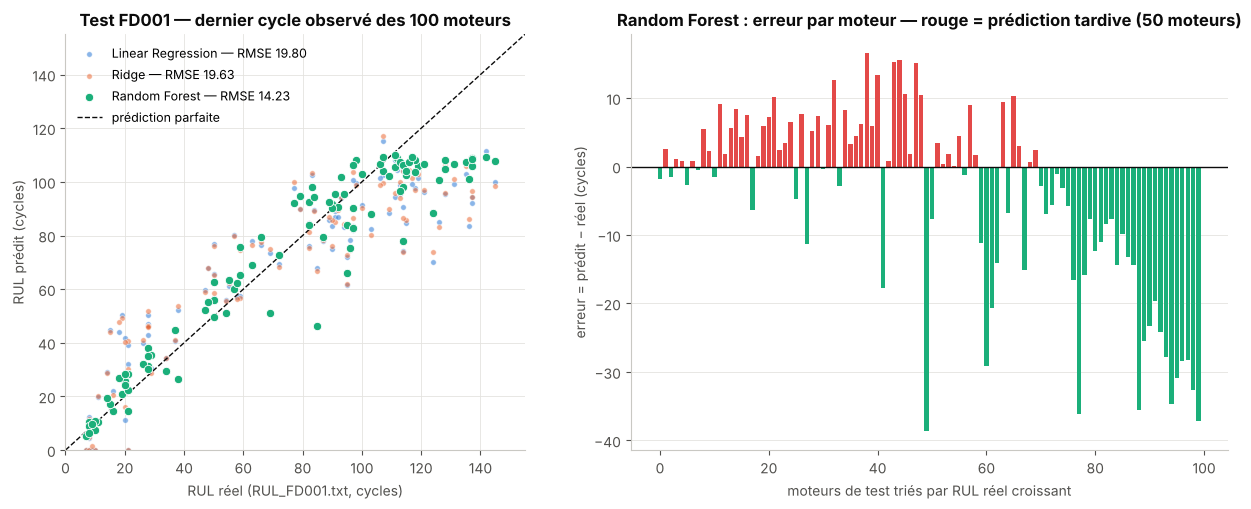

,lignes,MAE,RMSE,biais_moyen
tranche,,,,
0–25,19,3.46,4.38,1.94
25–75,24,7.10,8.38,4.01
75–127,47,10.93,14.38,-6.02
> 127,10,28.71,29.16,-28.71


,moteurs,MAE
historique < 50 cycles,7,13.85
historique ≥ 50 cycles,93,10.11


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
lim = [0, max(test_results["RUL_true"].max(), max(p.max() for p in test_pred.values())) + 10]
for m in MODEL_NAMES:
    is_sel = m == SELECTED_MODEL
    ax.scatter(test_results["RUL_true"], test_results[f"pred_{m}"], s=36 if is_sel else 16,
               color=MODEL_COLORS[m], alpha=1 if is_sel else 0.55, edgecolor="white", linewidth=0.6,
               label=f"{MODEL_LABELS[m]} — RMSE {test_metrics[m]['RMSE']:.2f}", zorder=3 if is_sel else 2)
ax.plot(lim, lim, color=INK, ls="--", lw=1, label="prédiction parfaite")
ax.set(xlim=lim, ylim=lim, xlabel="RUL réel (RUL_FD001.txt, cycles)", ylabel="RUL prédit (cycles)",
       title="Test FD001 — dernier cycle observé des 100 moteurs")
ax.legend(loc="upper left", fontsize=9)

ax = axes[1]
ordered = test_results.sort_values("RUL_true").reset_index(drop=True)
err = ordered[f"erreur_{SELECTED_MODEL}"]
ax.bar(ordered.index, err, color=np.where(err > 0, "#e34948", MODEL_COLORS[SELECTED_MODEL]), width=0.8)
ax.axhline(0, color=INK, lw=1)
ax.set(xlabel="moteurs de test triés par RUL réel croissant", ylabel="erreur = prédit − réel (cycles)",
       title=f"{MODEL_LABELS[SELECTED_MODEL]} : erreur par moteur — rouge = prédiction tardive ({TEST_N_LATE} moteurs)")
ax.grid(axis="x", visible=False)
save_figure(fig, "11_test_pred_vs_reel")
plt.show()

test_bands = rul_band_table(test_results["RUL_true"], test_results[f"erreur_{SELECTED_MODEL}"], RUL_BANDS)
short_history = test_results["dernier_cycle_observe"] < 50
display(test_bands.round(2))
pd.DataFrame({"moteurs": [int(short_history.sum()), int((~short_history).sum())],
              "MAE": [test_results.loc[short_history, f"erreur_{SELECTED_MODEL}"].abs().mean(),
                      test_results.loc[~short_history, f"erreur_{SELECTED_MODEL}"].abs().mean()]},
             index=["historique < 50 cycles", "historique ≥ 50 cycles"]).round(2)

**Lecture.** Le test confirme la hiérarchie établie en validation, sans qu'aucune décision n'ait été prise à partir de lui. Les erreurs restantes du modèle retenu se répartissent en deux groupes : des **prédictions tardives** près de la panne (barres rouges à gauche), les plus coûteuses dans le score NASA, et des **prédictions prudentes** pour les moteurs encore loin de la panne (effet du plafond).

## 18. Sauvegarde des métriques et artefacts

| Fichier (`artifacts/baseline_fd001/`) | Contenu |
|---|---|
| `baseline_metrics.json` | Configuration figée, CV, validation, test des trois modèles, traçabilité |
| `model_selection.json` | Sélection écrite **avant** la lecture du test |
| `baseline_rul_fd001.joblib` | Modèle retenu (non versionné) |
| `test_predictions.csv` | RUL réel et prédit par les trois modèles, au dernier cycle observé des 100 moteurs de test |

Les résultats intermédiaires (grilles de validation croisée, prédictions ligne à ligne de la validation, importances par permutation) sont affichés dans les sections 8 à 15 et ne sont pas exportés : ils se régénèrent en réexécutant le notebook.

In [31]:
def to_builtin(obj):
    # Convertit récursivement NumPy / pandas en types JSON (NaN -> null, flottants arrondis à 4 décimales).
    if isinstance(obj, dict):
        return {str(k): to_builtin(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_builtin(v) for v in obj]
    if isinstance(obj, (bool, np.bool_)):
        return bool(obj)
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, (np.floating, float)):
        return None if not np.isfinite(obj) else round(float(obj), 4)
    return obj


baseline_metrics = {
    "dataset": "FD001",
    "notebook": "02_baseline_fd001.ipynb",
    "version": 2,
    "final_config": FINAL_CONFIG,
    "evaluation_horizon": EVAL_HORIZON,
    "cross_validation": {
        "method": f"GroupKFold(n_splits={N_SPLITS}) par unit_id sur les 80 moteurs d'analyse",
        "per_model": {m: {"config": selection_record["per_model"][m], "mean": FINAL_CV[m].mean().to_dict(),
                          "std": FINAL_CV[m].std(ddof=1).to_dict(), "folds_RMSE_zone": FINAL_CV[m]["RMSE_zone"].tolist()}
                      for m in MODEL_NAMES},
        "ranking": ranking,
        "leader_vs_runner_up": LEADER_GAIN,
        "adopted_ablation": ADOPTED_ABLATION,
        "negative_predictions_before_clipping": N_NEGATIVE,
    },
    "validation_20_engines": {"engines": VALIDATION_ENGINES, "trained_on": "80 moteurs d'analyse",
                              "metrics": validation_metrics, "ranking": VALIDATION_RANKING,
                              "same_ranking_as_cv": SAME_RANKING},
    "test_fd001": {"protocol": "dernier cycle observé de chaque moteur, comparé à RUL_FD001.txt (lu une seule fois, "
                               "après gel du pipeline)",
                   "official_model": SELECTED_MODEL, "metrics": test_metrics,
                   "n_late_predictions_official": TEST_N_LATE},
    "traceability": {"raw_files_sha256": {**RAW_SHA256, "RUL_FD001.txt": RUL_TEST_SHA256},
                     "eda_split_file": "artifacts/eda_fd001/fd001_engine_split.json",
                     "versions": VERSIONS, "random_state": RANDOM_STATE},
}

if SAVE_OUTPUTS:
    (ARTIFACT_DIR / "baseline_metrics.json").write_text(
        json.dumps(to_builtin(baseline_metrics), indent=2, ensure_ascii=False), encoding="utf-8")
    test_results.round(4).to_csv(ARTIFACT_DIR / "test_predictions.csv", index=False)

reloaded = json.loads((ARTIFACT_DIR / "baseline_metrics.json").read_text(encoding="utf-8"))
assert reloaded["test_fd001"]["metrics"][SELECTED_MODEL]["RMSE"] == round(test_metrics[SELECTED_MODEL]["RMSE"], 4)
print(f"Durée totale du notebook : {(time.time() - NOTEBOOK_START) / 60:.1f} min")
pd.DataFrame([(p.parent.relative_to(PROJECT_ROOT).as_posix(), p.name, f"{p.stat().st_size / 1024:.1f} Ko")
              for d in (ARTIFACT_DIR, FIGURE_DIR) for p in sorted(d.iterdir()) if p.is_file()],
             columns=["dossier", "fichier", "taille"])

Durée totale du notebook : 13.6 min


,dossier,fichier,taille
0,artifacts/baseline_fd001,baseline_metrics.json,7.6 Ko
1,artifacts/baseline_fd001,baseline_rul_fd001.joblib,20991.5 Ko
2,artifacts/baseline_fd001,model_selection.json,0.7 Ko
3,artifacts/baseline_fd001,test_predictions.csv,5.8 Ko
4,reports/figures/baseline_fd001,01_features_temporelles.png,193.5 Ko
5,reports/figures/baseline_fd001,02_choix_features_temporelles.png,82.2 Ko
6,reports/figures/baseline_fd001,03_choix_plafond_rul.png,87.4 Ko
7,reports/figures/baseline_fd001,04_hyperparametres.png,118.9 Ko
8,reports/figures/baseline_fd001,05_selection_modele_cv.png,116.5 Ko
9,reports/figures/baseline_fd001,06_ablations.png,76.3 Ko


## 19. Conclusion

### Résultats obtenus (valeurs réelles de cette exécution)

| Modèle | Features | Cap | Hyperparamètres | CV RMSE zone (80 moteurs) | Validation RMSE zone (20 moteurs) | **Test RMSE** | Test MAE | Test R² | Score NASA |
|---|---|---|---|---|---|---|---|---|---|
| Linear Regression | écart début de vie 20 | 110 | — | 17,16 ± 0,51 | 16,46 | 19,80 | 15,70 | 0,773 | 569,6 |
| Ridge | écart début de vie 20 | 110 | `alpha` = 1000 | 16,81 ± 0,48 | 16,31 | 19,63 | 15,59 | 0,777 | 544,2 |
| **Random Forest (retenu)** | moyenne 30 + pente 30 + écart 20 | 110 | 100 arbres, `min_samples_leaf` = 5, `max_features` = 0,33 | **12,90 ± 0,47** | **11,41** | **14,23** | **10,37** | **0,883** | **239,2** |

Le résultat officiel du baseline est celui de la **Random Forest** : **RMSE = 14,23 cycles sur le test NASA FD001**, contre 22,69 pour la v1 (Ridge sur mesures instantanées), soit une erreur réduite de 37 %, et un score NASA divisé par plus de 4.

### Réponses aux questions de départ

- **Q1 — Mesures instantanées.** Avec le RUL plafonné à 110, les trois modèles restent proches (RMSE zone de 18,90 pour la Random Forest, 20,23 pour les modèles linéaires) : sans historique, aucun modèle ne voit la vitesse de dégradation.
- **Q2 — Features temporelles.** Elles apportent un **gain réel, sur chacun des 5 folds**. Les modèles linéaires profitent surtout de l'**écart au début de vie** (20,23 → 17,16) ; la Random Forest profite surtout de la **pente** et de la combinaison des trois familles (18,90 → 12,98 avant réglage des hyperparamètres).
- **Q3 — Plafond et hyperparamètres.** Le plafond **110** est optimal pour les trois modèles. Ridge gagne maintenant à être régularisé (`alpha` = 1000) ; la Random Forest est peu sensible à ses réglages.
- **Q4 — Choix du modèle.** La Random Forest bat Ridge sur **5 folds sur 5** (gain moyen de 3,91 cycles). Le choix a été fait en validation croisée, **confirmé sur les 20 moteurs de validation** (même classement, Random Forest meilleure sur les 20 moteurs sur 20), puis **figé et enregistré avant la lecture du test**.
- **Q5 — Ablations de l'EDA.** Aucune variante ne gagne sur les 5 folds : les 17 features de base sont conservées. Ajouter `cycle` améliore 4 folds sur 5 (gain moyen 0,41 cycle), ce qui ne suffit pas selon la règle déclarée. Retirer `sensor_9` et `sensor_14` est la variante la plus pénalisante (+1,58 cycle de RMSE) : malgré leur comportement à deux régimes, ces capteurs sont utiles.
- **Q6 — Erreurs et interprétation.** La Random Forest est très précise près de la panne (MAE de 2,85 cycles pour un RUL réel ≤ 25 en validation). Elle ne produit **aucune** prédiction négative, contrairement aux modèles linéaires (565 et 530 prédictions négatives avant clipping). Ses prédictions s'appuient d'abord sur les **moyennes glissantes**, puis sur l'**écart au début de vie** et les **pentes** ; les mesures instantanées seules ne comptent presque plus.
- **Q7 — Test.** RMSE de 14,23 cycles, cohérent avec la validation. **50 moteurs sur 100** reçoivent une prédiction tardive, mais d'au plus 16,55 cycles.

### Limites du baseline

1. **Mémoire courte et fixe** : les features résument 30 cycles avec des statistiques choisies à la main (moyenne, pente) ; un modèle séquentiel peut apprendre lui-même quels motifs temporels comptent.
2. **Plafond = choix de modélisation** : au-delà de 110 cycles, le modèle ne distingue pas un moteur neuf d'un moteur à mi-vie. Acceptable pour l'alerte, pas pour la planification à long terme.
3. **Prédictions tardives** : la moitié des moteurs de test reçoivent un RUL légèrement surestimé, la direction la plus coûteuse en maintenance ; à prendre en compte dans le Health Score et les seuils d'alerte (S5).
4. **Pas d'incertitude** : le modèle donne une valeur, pas un intervalle de confiance.
5. **Validation limitée** : 20 moteurs de validation, aucun de plus de 269 cycles ; un seul sous-ensemble (FD001) de données **simulées**.
6. **Coût** : la Random Forest pèse environ 20 Mo et prend quelques secondes à entraîner, contre quelques Ko pour Ridge ; c'est sans conséquence pour l'API, mais Ridge reste le meilleur choix si l'interprétabilité prime.

### Suite du projet

- **S4 — LSTM / GRU** : fenêtres W ∈ {20, 30}, même split, même critère (RMSE zone en GroupKFold), même protocole de test. **Référence à battre : RMSE test = 14,23** (`baseline_metrics.json`). Un modèle séquentiel moins bon que ce baseline est un résultat valide, à analyser.
- **Baseline** : tester Gradient Boosting, ou `cycle` avec une règle de sélection moins stricte, en gardant le même protocole.
- **Industrialisation** : le modèle se recharge avec `joblib` et ses features se recalculent avec `ml.src.features.build_feature_set` : c'est la base de l'inférence de l'API FastAPI (S6).

## 20. Vérification automatique des chiffres cités

**Objectif.** Règle 6 du README : chaque chiffre de la conclusion provient de l'exécution. Cette cellule les recalcule et échoue si l'un d'eux ne correspond plus (après une modification du code ou des données, par exemple).

In [32]:
# Chaque valeur citée dans la conclusion est recalculée à partir des objets du notebook.
# Si une assertion échoue, la conclusion ne correspond plus à l'exécution : il faut la mettre à jour.
def close(value, expected, ndigits):
    return round(float(value), ndigits) == expected


cv_mean = lambda m, k="RMSE_zone": FINAL_CV[m][k].mean()
fs = feature_set_results.set_index(["modèle", "features"])["RMSE_zone"]
abl = ablation_results["gain"]
checks = {
    "modèle retenu = Random Forest": SELECTED_MODEL == "RandomForest",
    "features LR / Ridge = écart 20": SELECTED_SPEC["LinearRegression"] == SELECTED_SPEC["Ridge"] == "écart début de vie 20",
    "features RF = combinaison": SELECTED_SPEC["RandomForest"] == "moyenne 30 + pente 30 + écart 20",
    "cap 110 pour les trois": set(SELECTED_CAP.values()) == {110},
    "alpha = 1000": SELECTED_PARAMS["Ridge"] == {"alpha": 1000.0},
    "RF : leaf 5, max_features 0,33, 100 arbres": SELECTED_PARAMS["RandomForest"] == {"n_estimators": 100, "min_samples_leaf": 5, "max_features": 0.33},
    "CV LR 17,16 ± 0,51": close(cv_mean("LinearRegression"), 17.16, 2) and close(FINAL_CV["LinearRegression"]["RMSE_zone"].std(ddof=1), 0.51, 2),
    "CV Ridge 16,81 ± 0,48": close(cv_mean("Ridge"), 16.81, 2) and close(FINAL_CV["Ridge"]["RMSE_zone"].std(ddof=1), 0.48, 2),
    "CV RF 12,90 ± 0,47": close(cv_mean("RandomForest"), 12.90, 2) and close(FINAL_CV["RandomForest"]["RMSE_zone"].std(ddof=1), 0.47, 2),
    "validation LR / Ridge / RF = 16,46 / 16,31 / 11,41": [round(validation_metrics[m]["RMSE_zone"], 2) for m in MODEL_NAMES] == [16.46, 16.31, 11.41],
    "test LR": [round(test_metrics["LinearRegression"][k], n) for k, n in (("RMSE", 2), ("MAE", 2), ("R2", 3), ("NASA_score", 1))] == [19.80, 15.70, 0.773, 569.6],
    "test Ridge": [round(test_metrics["Ridge"][k], n) for k, n in (("RMSE", 2), ("MAE", 2), ("R2", 3), ("NASA_score", 1))] == [19.63, 15.59, 0.777, 544.2],
    "test RF": [round(test_metrics["RandomForest"][k], n) for k, n in (("RMSE", 2), ("MAE", 2), ("R2", 3), ("NASA_score", 1))] == [14.23, 10.37, 0.883, 239.2],
    "réduction de 37 % vs v1 (22,69)": close(1 - test_metrics["RandomForest"]["RMSE"] / 22.69, 0.37, 2),
    "score NASA divisé par plus de 4 vs v1 (1047,1)": 1047.1 / test_metrics["RandomForest"]["NASA_score"] > 4,
    "instantané cap 110 : RF 18,90, linéaires 20,23": close(fs[("RandomForest", "instantané")], 18.90, 2) and close(fs[("Ridge", "instantané")], 20.23, 2) and close(fs[("LinearRegression", "instantané")], 20.23, 2),
    "LR écart 20 = 17,16": close(fs[("LinearRegression", "écart début de vie 20")], 17.16, 2),
    "RF combinaison avant réglage = 12,98": close(fs[("RandomForest", "moyenne 30 + pente 30 + écart 20")], 12.98, 2),
    "RF : la pente est la meilleure famille seule": fs.loc["RandomForest"].drop("instantané").idxmin() == "moyenne 30 + pente 30 + écart 20"
        and fs[("RandomForest", "pente 30")] < min(fs[("RandomForest", "moyenne 30")], fs[("RandomForest", "écart début de vie 20")]),
    "RF bat Ridge 5/5, gain 3,91": runner_up == "Ridge" and LEADER_GAIN["folds_improved"] == 5 and close(LEADER_GAIN["gain_mean"], 3.91, 2),
    "même classement en validation, 20/20 moteurs": SAME_RANKING and ENGINES_IMPROVED == 20 == len(VALIDATION_ENGINES),
    "aucune ablation adoptée": ADOPTED_ABLATION is None,
    "+ cycle : 4/5 folds, gain 0,41": ablation_results.loc["+ cycle", "folds_gagnés"] == 4 and close(abl["+ cycle"], 0.41, 2),
    "retrait sensor_9/14 = pire, +1,58": abl.idxmin() == "- sensor_9, sensor_14" and close(-abl.min(), 1.58, 2),
    "RF : MAE 2,85 pour RUL ≤ 25": close(band_tables["Random Forest"].loc["0–25", "MAE"], 2.85, 2),
    "négatives : 565 / 530 / 0": [N_NEGATIVE[MODEL_LABELS[m]] for m in MODEL_NAMES] == [565, 530, 0],
    "importance : moyenne > écart > pente > instantanée": list(family_importance.index) == ["moyenne 30", "écart début de vie", "pente 30", "instantanée"],
    "50 prédictions tardives, au plus 16,55": TEST_N_LATE == 50 and close(test_results["erreur_RandomForest"].max(), 16.55, 2),
    "modèle ≈ 20 Mo": 15 < MODEL_PATH.stat().st_size / 1024 ** 2 < 25,
}
report = pd.Series(checks, name="vérifié")
failed = report[~report].index.tolist()
assert not failed, f"Chiffres de la conclusion à mettre à jour : {failed}"
print(f"{len(report)} groupes de chiffres cités vérifiés automatiquement : tous conformes à l'exécution.")

29 groupes de chiffres cités vérifiés automatiquement : tous conformes à l'exécution.
